# Nhóm 07 — Khai phá dữ liệu tuyển dụng khối nghề phần mềm

## Giai đoạn 1: Giữ nguyên bản cào mới nhất
Chọn bản cào mới nhất theo timestamp trong tên và sao chép thành `raw_jobs_data.csv`, giữ nguyên dữ liệu. Chạy lại sẽ ghi đè bản sao này, không sửa file cào nguồn.

In [1]:
from pathlib import Path
import shutil
import re
from bs4 import BeautifulSoup
from stopwordsiso import stopwords

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
INPUT_FILE = max(RAW_DIR.glob("raw_data_????????_??????.csv"), key=lambda p: p.name)
RAW_PATH = PROJECT_ROOT / "notebooks" / "raw_jobs_data.csv"
shutil.copyfile(INPUT_FILE, RAW_PATH)
print(f"Đã sao chép {INPUT_FILE.name} --> {RAW_PATH.name}")

Đã sao chép raw_data_20261115_014436.csv --> raw_jobs_data.csv


## Giai đoạn 2: THỰC THI QUY TRÌNH KHAI PHÁ DỮ LIỆU TRÊN DỮ LIỆU THỰC TẾ
### Bước 2.1: Tiền xử lý và Làm sạch dữ liệu tuyển dụng

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Đọc file raw_jobs_data.csv vào DataFrame
df = pd.read_csv(RAW_PATH).rename(columns={
    "Tieu_De": "job_title", "Ten_Cong_Ty": "company_name", "Dia_Diem": "location_raw",
    "Muc_Luong_Goc": "salary_raw", "Kinh_Nghiem": "experience_raw",
    "Mo_Ta_Cong_Viec": "description_raw", "Yeu_Cau": "requirements_raw",
    "Quyen_Loi": "benefits_raw", "Cap_Bac": "level_raw",
    "URL_Goc": "source_url", "Timestamp": "scraped_at"
})
print(df.shape)
df.head(10)

(867, 11)


,job_title,company_name,location_raw,salary_raw,experience_raw,description_raw,requirements_raw,benefits_raw,level_raw,source_url,scraped_at
0,Chuyên Viên Kiểm Tra Chất Lượng Phần Mềm - Tester,CÔNG TY TNHH P.A VIỆT NAM,"Hồ Chí Minh: 344 Huỳnh Tấn Phát, Phường Tân Th...",10 - 20 triệu,1 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/chuyen-vien-kiem...,2026-11-15T01:45:11+07:00
1,Quản Lý Dự Án Hạ Tầng Facilities - PM,SVTECH,"Hồ Chí Minh: 2A Phan Thúc Duyện, Phường Tân Sơ...",Thoả thuận,3 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/quan-ly-du-an-ha...,2026-11-15T01:45:23+07:00
2,Chuyên Viên Kiểm Thử Phần Mềm,TTI JSC,"Hồ Chí Minh: 370 Trường Chinh, Phường Tân Bình...",10 - 15 triệu,2 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/chuyen-vien-kiem...,2026-11-15T01:45:37+07:00
3,Fullstack Developer,Tập đoàn FPT,"Hà Nội: toà FPT, số 10 Phạm Văn Bạch, Cầu Giấy...",Thoả thuận,2 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/fullstack-develo...,2026-11-15T01:45:49+07:00
4,QA Engineer (Pre-Deployment Codebase Testing),CÔNG TY CỔ PHẦN ĐẦU TƯ VÀ PHÁT TRIỂN NĂNG LƯỢN...,Hồ Chí Minh: Phường Bình Trưng (Phường Bình Tr...,Thoả thuận,3 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/qa-engineer-pre-...,2026-11-15T01:46:01+07:00
5,Fullstack Developer ( NodeJS / PHP /Go) – E-Co...,XIPAT FLEXIBLE SOLUTIONS COMPANY LIMITED,"Hà Nội: Số 18 ngõ 11 Thái Hà, Phường Đống Đa (...",Thoả thuận,5 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/fullstack-develo...,2026-11-15T01:46:13+07:00
6,Nhân Viên Tư Vấn Triển Khai Phần Mềm Website (...,CÔNG TY TNHH CÔNG NGHỆ PHẦN MỀM NASANI,Hồ Chí Minh: (Tất cả các phường) - Phạm vi làm...,7 - 20 triệu,Không yêu cầu,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/nhan-vien-tu-van...,2026-11-15T01:46:25+07:00
7,Java Developer,"Cathay Insurance Co., Ltd","Hồ Chí Minh: Lim Tower 3, 29A Nguyễn Đình Chiể...",Thoả thuận,1 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/java-developer/8...,2026-11-15T01:46:37+07:00
8,Tester (Manual/Automation) – Thu Nhập 18-24 Tr...,Công ty TNHH Thiết kế T&T,"Hà Nội: Tòa nhà VPI 167 Trung Kính, Phường Yên...",18 - 24 triệu,2 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/tester-manual-au...,2026-11-15T01:46:48+07:00
9,Nhân Viên Tư Vấn Triển Khai Phần Mềm Website (...,CÔNG TY TNHH CÔNG NGHỆ PHẦN MỀM NASANI,Hồ Chí Minh: (Tất cả các phường) - Phạm vi làm...,7 - 20 triệu,Không yêu cầu,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/nhan-vien-tu-van...,2026-11-15T01:47:01+07:00


===> Dữ liệu thô có 867 dòng và 11 cột

In [4]:
df.describe()

,job_title,company_name,location_raw,salary_raw,experience_raw,description_raw,requirements_raw,benefits_raw,level_raw,source_url,scraped_at
count,867,867,867,867,867,867,867,867,867,867,867
unique,770,467,629,174,8,851,863,820,6,867,867
top,Product Owner,Công ty Cổ phần Công nghệ Phần mềm Tinh Vân,Hà Nội: Phường Yên Hòa (Phường Yên Hòa thuộc q...,Thoả thuận,3 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/chuyen-vien-kiem...,2026-11-15T01:45:11+07:00
freq,13,18,9,430,217,2,2,4,550,1,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 867 entries, 0 to 866
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   job_title         867 non-null    str  
 1   company_name      867 non-null    str  
 2   location_raw      867 non-null    str  
 3   salary_raw        867 non-null    str  
 4   experience_raw    867 non-null    str  
 5   description_raw   867 non-null    str  
 6   requirements_raw  867 non-null    str  
 7   benefits_raw      867 non-null    str  
 8   level_raw         867 non-null    str  
 9   source_url        867 non-null    str  
 10  scraped_at        867 non-null    str  
dtypes: str(11)
memory usage: 7.3 MB


==> Bộ dữ liệu không có ô nào null

In [6]:
salary_col = df['salary_raw'].copy()
salary = salary_col.astype('string').str.strip().str.lower()

number_pattern = r'\d+(?:[.,]\d+)*'
amount_pattern = rf'(?:(?:usd|\$)\s*)?{number_pattern}\s*(?:triệu|tr|m|usd|\$)?'

# Phân loại dạng lương
salary_patterns = {
    'Thỏa thuận': r'th(?:ỏa|oả) thuận',
    'Khoảng lương': rf'{amount_pattern}\s*[-–—]\s*{amount_pattern}',
    'Cận trên': rf'(?:tới|up\s*to)\s*{amount_pattern}',
    'Cận dưới': rf'(?:từ|from)\s*{amount_pattern}',
    'Mức cụ thể': rf'{amount_pattern}',
}

salary_type = pd.Series('Khác', index=salary.index)
for label, pattern in salary_patterns.items():
    salary_type.loc[salary.str.fullmatch(pattern, na=False)] = label

# Phân loại đơn vị
salary_unit = pd.Series('Không ghi đơn vị', index=salary.index)
salary_unit.loc[salary.str.contains(r'(?:triệu|tr|m)$', na=False)] = 'Triệu'
salary_unit.loc[salary.str.contains(r'usd|\$', na=False)] = 'USD / $'
salary_unit.loc[salary_type.eq('Thỏa thuận')] = 'Không áp dụng'

thieu = salary.isna() | salary.eq('').fillna(False)
salary_type.loc[thieu] = 'Thiếu'
salary_unit.loc[thieu] = 'Không áp dụng'

# Bảng thống kê: Loại | Triệu | USD / $ | ... | Tổng
df_stats = pd.crosstab(salary_type, salary_unit).reindex(
    index=[*salary_patterns.keys(), 'Thiếu', 'Khác'],
    columns=['Triệu', 'USD / $', 'Không ghi đơn vị', 'Không áp dụng'],
    fill_value=0
)
df_stats['Tổng'] = df_stats.sum(axis=1)
df_thong_ke = df_stats.rename_axis('Loại').reset_index()

display(df_thong_ke)

col_0,Loại,Triệu,USD / $,Không ghi đơn vị,Không áp dụng,Tổng
0,Thỏa thuận,0,0,0,430,430
1,Khoảng lương,334,6,0,0,340
2,Cận trên,86,5,0,0,91
3,Cận dưới,6,0,0,0,6
4,Mức cụ thể,0,0,0,0,0
5,Thiếu,0,0,0,0,0
6,Khác,0,0,0,0,0


===> Sau khảo sát cột `Muc_Luong_Goc` cho thấy cột dữ liệu này có `4` loại lương gồm `thỏa thuận`, `khoảng lương`, `cận trên`, `cận dưới`, trong đó:
- `Khoảng lương` có `334` loại `tiền Việt` và `6` loại `tiền Đô`
- `Cận trên` có `86` loại `tiền Việt` và `5` loại `tiền Đô`
- `Cận dưới` có `6` loại `tiền Việt` và `không có` loại `tiền Đô`

In [7]:
# Chọn tỉ giá USD sang VND để quy đổi các mức lương USD sang VND
usd_exchange_rate = 26000 

df_clean = df.copy()
# Kiểm tra các dòng trùng lặp dựa trên tất cả các cột ngoại trừ source_url và scraped_at
content_columns = df_clean.columns.difference(
    ["source_url", "scraped_at"]
)

duplicates = df_clean.duplicated(subset=content_columns)
display(df_clean.loc[duplicates, ["job_title", "source_url"]])

df_clean = df_clean.loc[~duplicates].copy()

# Format lại cột salary_raw
def parse_salary(text):
    text = text.strip().lower()

    if "thỏa thuận" in text or "thoả thuận" in text:
        return None, None

    is_usd = "usd" in text or "$" in text
    multiplier = usd_exchange_rate if is_usd else 1_000_000

    numbers = re.findall(r'\d+(?:[.,]\d+)*', text)
    numbers = [
        float(so.replace(",", "") if is_usd else so.replace(",", "."))
        * multiplier
        for so in numbers
    ]

    if text.startswith(("tới", "up to", "upto")):
        return None, numbers[0]

    if text.startswith(("từ", "from")):
        return numbers[0], None

    return numbers[0], numbers[-1]

df_clean['salary_type'] = salary_type

df_clean[['salary_min', 'salary_max']] = pd.DataFrame(
    df_clean['salary_raw'].apply(parse_salary).tolist(),
    index=df_clean.index,
    dtype='float64'
)

display(df_clean[['salary_raw', 'salary_min', 'salary_max','salary_type']].head(10))

,job_title,source_url
427,Trưởng Phòng IT ( Công Nghệ Thông Tin ),https://www.topcv.vn/viec-lam/truong-phong-it-...


,salary_raw,salary_min,salary_max,salary_type
0,10 - 20 triệu,10000000.0,20000000.0,Khoảng lương
1,Thoả thuận,NaN,NaN,Thỏa thuận
2,10 - 15 triệu,10000000.0,15000000.0,Khoảng lương
3,Thoả thuận,NaN,NaN,Thỏa thuận
4,Thoả thuận,NaN,NaN,Thỏa thuận
5,Thoả thuận,NaN,NaN,Thỏa thuận
6,7 - 20 triệu,7000000.0,20000000.0,Khoảng lương
7,Thoả thuận,NaN,NaN,Thỏa thuận
8,18 - 24 triệu,18000000.0,24000000.0,Khoảng lương
9,7 - 20 triệu,7000000.0,20000000.0,Khoảng lương


===> Thực hiện chuẩn hóa cột `salary_raw` thành hai cột `salary_min`, `salary_max`, quy đổi về VNĐ theo tỷ giá đã chọn. Gán nhãn `salary_type` gồm 4 loại xuất hiện trong dữ liệu: `Thỏa thuận`, `Khoảng lương`, `Cận trên`, `Cận dưới`. Những cận không xác định được giữ là giá trị thiếu (NaN).

In [8]:
df['location_raw'].head(5)

0    Hồ Chí Minh: 344 Huỳnh Tấn Phát, Phường Tân Th...
1    Hồ Chí Minh: 2A Phan Thúc Duyện, Phường Tân Sơ...
2    Hồ Chí Minh: 370 Trường Chinh, Phường Tân Bình...
3    Hà Nội: toà FPT, số 10 Phạm Văn Bạch, Cầu Giấy...
4    Hồ Chí Minh: Phường Bình Trưng (Phường Bình Tr...
Name: location_raw, dtype: str

===> Khảo sát sơ qua địa chỉ của cột `location_raw` hầu hết đều có dạng `Tỉnh thành: Địa chỉ`. Bước tiếp theo sẽ chuẩn hóa cột `location_raw` về tỉnh thành

In [9]:
df_clean['province'] = df_clean['location_raw'].str.split(':').str[0].str.strip()
print(df_clean['province'].groupby(df_clean['province']).size().sort_values(ascending=False))

province
Hà Nội         627
Hồ Chí Minh    178
Đà Nẵng         20
Bắc Ninh         7
Đồng Nai         6
Khánh Hòa        4
Thái Nguyên      4
Tây Ninh         3
Hải Phòng        3
Nhật Bản         3
Quảng Trị        2
Gia Lai          1
Hưng Yên         1
Ninh Bình        1
Nghệ An          1
Lâm Đồng         1
Phú Thọ          1
Quảng Ninh       1
Vĩnh Long        1
Đắk Lắk          1
Name: province, dtype: int64


In [10]:
# Xử lý các dòng có giá trị province không thuộc danh sách các tỉnh thành Việt Nam
vietnam_provinces = [
    "Hà Nội", "Hải Phòng", "Huế", "Đà Nẵng", "Hồ Chí Minh", "Cần Thơ",
    "Cao Bằng", "Điện Biên", "Lai Châu", "Sơn La", "Lạng Sơn",
    "Quảng Ninh", "Thanh Hóa", "Nghệ An", "Hà Tĩnh",
    "Tuyên Quang", "Lào Cai", "Thái Nguyên", "Phú Thọ", "Bắc Ninh",
    "Hưng Yên", "Ninh Bình", "Quảng Trị", "Quảng Ngãi", "Gia Lai",
    "Khánh Hòa", "Lâm Đồng", "Đắk Lắk", "Đồng Nai", "Tây Ninh",
    "Vĩnh Long", "Đồng Tháp", "Cà Mau", "An Giang",
]
print(f"Số lượng dòng trước khi lọc: {len(df_clean)}")
is_vietnam =  df_clean["province"].isin(vietnam_provinces)

# In các dòng không khớp để kiểm tra
display(df_clean.loc[
    ~is_vietnam, ["job_title", "province", "source_url"]
])

# Chỉ giữ các dòng khớp
df_clean = df_clean.loc[is_vietnam].copy()
print(f"Số lượng dòng sau khi lọc: {len(df_clean)}")

Số lượng dòng trước khi lọc: 866


,job_title,province,source_url
174,Kỹ Sư Cầu Nối ( BrSE ),Nhật Bản,https://www.topcv.vn/viec-lam/ky-su-cau-noi-br...
279,C# Developer,Nhật Bản,https://www.topcv.vn/viec-lam/c-developer/1805...
314,Kỹ Sư Cầu Nối,Nhật Bản,https://www.topcv.vn/viec-lam/ky-su-cau-noi/23...


Số lượng dòng sau khi lọc: 863


In [11]:
# Đếm tần suất các giá trị trong cột 'experience_raw', bao gồm cả giá trị NaN
print(df_clean['experience_raw'].value_counts(dropna=False))

experience_raw
3 năm            215
2 năm            213
1 năm            144
5 năm             77
Không yêu cầu     62
4 năm             57
Trên 5 năm        55
Dưới 1 năm        40
Name: count, dtype: int64


    Khảo sát cột `experience_raw` ta thấy có 8 loại kinh nghiệm và có sự phân chia hợp lý gồm:
1. `Dưới 1 năm`
2. `1 năm`
3. `2 năm`
4. `3 năm`
5. `4 năm`
6. `5 năm`
7. `Trên 5 năm`
8. `Không yêu cầu`

    ===> Không cần chuẩn hóa lại cột `experience_raw`.

In [12]:
df_clean = df_clean.rename(columns={'experience_raw': 'experience'}) 

#### Phần khảo sát dữ liệu có trong các văn bản mô tả, yêu cầu và quyền lợi

In [13]:
i=2
description = df_clean.iloc[i]['description_raw']
text = BeautifulSoup(description, 'html.parser').get_text('\n', strip=True)
print(text)

Chịu trách nhiệm phát triển các tính năng mới và bảo trì các tính năng đã phát triển
Thực hiện tất cả các hoạt động kiểm thử (thủ công và tự động) nhằm nâng cao chất lượng sản phẩm. Phối hợp chặt chẽ với các bộ phận liên quan (Lập trình viên, Chuyên viên phân tích nghiệp vụ, Chăm sóc khách hàng, Vận hành, v.v.) để đảm bảo triển khai sản phẩm thành công.
Phân tích và giải quyết các yêu cầu về kiểm thử tự động một cách có phương pháp, tỉ mỉ và có hệ thống, vận dụng kỹ năng phân tích và khả năng giải quyết vấn đề hiệu quả.
Tự động hóa các bài kiểm thử chức năng (Functional Testing), kiểm thử hồi quy (Regression Testing) và/hoặc kiểm thử chấp nhận về hiệu năng (Performance Acceptance Testing).
Chịu trách nhiệm toàn diện trong việc phát triển và mở rộng phạm vi kiểm thử tự động xuyên suốt hệ thống (End-to-End Automated Testing).
Tham gia với nhóm BA để lấy và phân tích yêu cầu từ khách hàng, bàn giao nghiệp vụ lại cho đội phát triển và đồng thời dựa vào đó đưa ra các đề xuất kiểm thử phù hợ

In [14]:
requirement = df_clean.iloc[i]['requirements_raw']
text = BeautifulSoup(requirement, 'html.parser').get_text('\n', strip=True)
print(text)

Yêu cầu ứng viên
●
Kiến thức & Kinh nghiệm:
Có bằng kỹ sư hoặc cử nhân thuộc các chuyên ngành liên quan như Khoa Học Máy Tính, Công Nghệ Thông Tin.
Có ít nhất 2 năm kinh nghiệm thực tế trong lĩnh vực kiểm thử phần mềm.
Có khả năng sử dụng AI Agents để thực hiện các công việc kiểm thử. Cụ thể như sau:
Chuẩn bị ngữ cảnh tốt, rõ ràng, đầy đủ cho AI.
Định hướng, giao nhiệm vụ và điều phối AI Agent thực hiện công việc.
Kiểm tra, đánh giá kết quả kiểm thử do AI tạo ra.
Đảm bảo phần mềm đạt chất lượng sau quá trình kiểm thử.
Có kiến thức vững chắc về quy trình phát triển phần mềm, đặc biệt là quy trình kiểm thử phần mềm.
Có kinh nghiệm chuyên sâu về kiểm thử thủ công (Manual Testing), bao gồm:
Phân tích yêu cầu (Requirement Analysis).
Xây dựng chiến lược kiểm thử (Test Strategy).
Xác định phương pháp tiếp cận kiểm thử (Test Approach).
Lập kế hoạch kiểm thử (Test Plan).
Áp dụng các kỹ thuật kiểm thử như kiểm thử hộp đen (Black-box Testing), kiểm thử dựa trên rủi ro (Risk-based Testing), kiểm t

In [15]:
benefit = df_clean.iloc[i]['benefits_raw']
text = BeautifulSoup(benefit, 'html.parser').get_text('\n', strip=True)
print(text)

Quyền lợi ứng viên
Mức lương cứng: 10 - 15 triệu / tháng (thoả thuận theo năng lực)
Tổng thu nhập ổn định từ: 15-20 triệu / tháng, bao gồm: Lương cứng + Thưởng KPI theo dự án, chiến dịch.
Được hưởng đầy đủ chế độ BHYT, BHXH theo quy định sau khi ký HĐLĐ chính thức.
Chế độ phúc lợi đầy đủ: Quà tặng sinh nhật, thưởng lễ, Tết, hiếu, hỉ, Trung thu, 8/3, 20/10 theo quy chế của Công ty và Công đoàn, khám sức khỏe định kỳ
Thưởng hàng năm từ 2-3 tháng lương tuỳ tình hình lợi nhuân công ty.
Đánh giá xem xét tăng lương định kỳ 2 lần 1 năm.
Làm việc trực tiếp với CTO có hơn 15 năm kinh nghiệm làm việc tại Hàn Quốc thuộc dự án AI của chính phủ. Được tham gia các khóa đào tạo nâng cao nghiệp vụ phục vụ cho công việc.
Môi trường làm việc năng động, trẻ trung, có nhiều cơ hội thăng tiến.
Phụ cấp: đồng phục, điện thoại.


In [16]:
# Chuẩn bị stopwords cho cả tiếng Việt và tiếng Anh
stop_words = set(stopwords("vi")) | set(stopwords("en"))

stop_words -= {
    "không", "chưa", "chẳng",
    "not", "no", "never",
    "c", "r", "go", "anh", "nhưng", "but", "cần", "bắt", "buộc", "without", "required"
}

# Làm sạch HTML và loại stopwords
def clean_text(html):
    if pd.isna(html):
        return ""

    text = BeautifulSoup(html, "html.parser").get_text(" ", strip=True)
    return " ".join(
        word for word in text.lower().split()
        if word.strip(".,;:!?()[]") not in stop_words
    )

# Làm sạch các cột văn bản
for field in ["description", "requirements", "benefits"]:
    df_clean[f"{field}_text"] = df_clean[f"{field}_raw"].apply(clean_text)

In [17]:
# Trích 2 mảng kỹ năng cần có và kỹ năng nên có từ tag 
def extract_skills(html):
    result = {
        "required_skills": [],
        "preferred_skills": [],
    }

    labels = {
        "kỹ năng cần có": "required_skills",
        "kỹ năng nên có": "preferred_skills",
        "required skills": "required_skills",
        "preferred skills": "preferred_skills",
    }

    if pd.notna(html):
        soup = BeautifulSoup(html, "html.parser")

        for tag in soup.select(".required-tag"):
            title = tag.select_one(".required-tag__content--title")
            content = tag.select_one(".required-tag__content--desc")

            if title and content:
                label = title.get_text(" ", strip=True).lower().strip(": ")
                key = labels.get(label)

                if key:
                    result[key].extend(
                        skill.strip().lower()
                        for skill in re.split(
                            r",\s*(?![^()]*\))",
                            content.get_text(" ", strip=True)
                        )
                        if skill.strip()
                    )

    # Bỏ trùng, giữ nguyên tên và thứ tự kỹ năng
    return pd.Series({
        key: list(dict.fromkeys(skills))
        for key, skills in result.items()
    })


skill_columns = ["required_skills", "preferred_skills"]

df_clean[skill_columns] = (
    df_clean["requirements_raw"].apply(extract_skills)
)

display(df_clean[skill_columns].head(10))

,required_skills,preferred_skills
0,"[kiến thức về kiểm thử phần mềm, kỹ năng viết ...","[bug tracking tools (jira, bugzilla), test aut..."
1,[],[]
2,"[git, java, javascript, tester, phân tích, non...",[]
3,[],[]
4,"[javascript, python, ai, typescript, ci cd pip...",[]
5,[],[]
6,"[business analyst, công nghệ thông tin]",[]
7,"[java, javascript framework]",[]
8,"[logic, bug reporting, software testing, respo...","[regression test, boundary value, abnormal tes..."
9,[],[]


===> Sau khi tách tag, một số tin có mảng kỹ năng rỗng. Điều này không có nghĩa tin không yêu cầu kỹ năng; nhà tuyển dụng có thể chỉ viết chúng trong mô tả hoặc nội dung yêu cầu.

 - Nhóm gộp `required_skills` và `preferred_skills`, loại bỏ trùng lặp để tạo cột `skills`, biểu diễn các kỹ năng được đề cập trong tin tuyển dụng, không phân biệt bắt buộc hay ưu tiên.

 - Với những dòng `skills` còn rỗng, nhóm tìm bổ sung trong `description_raw` và `requirements_raw`. Danh sách dùng để tìm được tổng hợp từ các tag kỹ năng đã thu thập. Nếu không tìm thấy kỹ năng phù hợp, giữ nguyên mảng rỗng, không tự suy đoán.

In [ ]:
# Tạo danh sách kỹ năng từ 2 cột required_skills và preferred_skills
skill_dictionary = sorted({
    skill
    for column in ["required_skills", "preferred_skills"]
    for skills in df_clean[column]
    for skill in skills
})

# Biên ký tự và ngữ cảnh phủ định cho nhánh tìm kỹ năng trong văn bản.
skill_patterns = {
    skill: re.compile(
        rf"(?<![\w.+#]){re.escape(skill)}(?![\w+#]|[.:]\s)" if skill == "c"
        else rf"(?<![\w.]){re.escape(skill)}(?!\w|\.\w)" if skill == "ai"
        else rf"(?<!\w){re.escape(skill)}(?!\w)", re.I)
    for skill in skill_dictionary
}
negative_before = re.compile(
    r"(?:không\s+(?:yêu\s+cầu|cần|bắt\s+buộc)\s*(?:về\s+)?|"
    r"no\s+(?:prior\s+)?(?:experience\s+(?:in|with)\s+)?|without\s+)$", re.I)
negative_after = re.compile(
    r"^\s*(?:không\s+(?:bắt\s+buộc|yêu\s+cầu)|(?:is\s+)?not\s+(?:required|mandatory))", re.I)

def skill_in_text(skill, text):
    for match in skill_patterns[skill].finditer(text):
        before = text[max(0, match.start()-60):match.start()]
        after = text[match.end():match.end()+60]
        if not negative_before.search(before) and not negative_after.search(after):
            return True
    return False

# Tạo cột skills từ 2 cột required_skills và preferred_skills, nếu cả 2 cột đều rỗng thì trích từ description_raw và requirements_raw
def collect_skills(row):
    skills = row["required_skills"] + row["preferred_skills"]

    if skills:
        return list(dict.fromkeys(skills))

    if pd.isna(row["requirements_raw"]):
        return []

    text = BeautifulSoup(row["requirements_raw"], "html.parser").get_text(" ", strip=True) + " " + BeautifulSoup(row["description_raw"], "html.parser").get_text(" ", strip=True)

    return [
        skill for skill in skill_dictionary
        if skill_in_text(skill, text)
    ]

df_clean["skills"] = df_clean.apply(collect_skills, axis=1)

display(df_clean[
    ["required_skills", "preferred_skills", "skills"]
].head(10))

,required_skills,preferred_skills,skills
0,"[kiến thức về kiểm thử phần mềm, kỹ năng viết ...","[bug tracking tools (jira, bugzilla), test aut...","[kiến thức về kiểm thử phần mềm, kỹ năng viết ..."
1,[],[],"[an ninh mạng, analysis, communication, data, ..."
2,"[git, java, javascript, tester, phân tích, non...",[],"[git, java, javascript, tester, phân tích, non..."
3,[],[],"[.net, ai, ai agent, angular, api, aws, azure,..."
4,"[javascript, python, ai, typescript, ci cd pip...",[],"[javascript, python, ai, typescript, ci cd pip..."
5,[],[],"[a/b testing, ai, ai tools, api, apis, backend..."
6,"[business analyst, công nghệ thông tin]",[],"[business analyst, công nghệ thông tin]"
7,"[java, javascript framework]",[],"[java, javascript framework]"
8,"[logic, bug reporting, software testing, respo...","[regression test, boundary value, abnormal tes...","[logic, bug reporting, software testing, respo..."
9,[],[],"[it, marketing, phần mềm, đào tạo]"


In [19]:
empty_skills = df_clean["skills"].map(len).eq(0)

print("Số dòng chưa tìm được kỹ năng:", empty_skills.sum())
display(df_clean.loc[empty_skills, ["job_title", "source_url"]])

Số dòng chưa tìm được kỹ năng: 0


,job_title,source_url


===> Đã điền đủ các skills vào ô dữ liệu trống

In [20]:
# Xem xét các giá trị trong cột level_raw
print(df_clean["level_raw"].value_counts(dropna=False))
print(f"Tổng số tin tuyển dụng: {len(df_clean)}")

level_raw
Nhân viên             547
Trưởng nhóm           202
Trưởng/Phó phòng       40
Thực tập sinh          37
Quản lý / Giám sát     34
Giám đốc                3
Name: count, dtype: int64
Tổng số tin tuyển dụng: 863


===> Ta thấy tổng có 863 tin tuyển dụng, có 6 cấp bậc và không có giá trị thiếu. Nhóm quyết định giữ các phân loại này để thực hiện các bước phân tích tiếp theo.

In [21]:
# Xuất file dữ liệu sạch
print(f"Kích thước dữ liệu sạch: {df_clean.shape[0]}")
columns_to_export = [
    "job_title",
    "company_name",
    "province",
    "description_text",
    "requirements_text",
    "benefits_text",
    "level_raw",
    "salary_min",
    "salary_max",
    "salary_type",
    "experience",
    "skills",
    "source_url",
    "scraped_at",
]
out_file = PROJECT_ROOT / "data" / "processed" / "clean_data.csv"
df_clean[columns_to_export].to_csv(out_file, index=False, encoding="utf-8-sig")
print(f"Đã xuất: 'clean_data.csv' ==> {out_file.parent.resolve()}")

Kích thước dữ liệu sạch: 863
Đã xuất: 'clean_data.csv' ==> F:\data-mining\data\processed


## Bước 2.2. Phân tích khám phá và thống kê mô tả

Phân tích phân bố lương theo cấp bậc, Top 15 kỹ năng và so sánh tuyển dụng giữa Hà Nội, TP.HCM, Đà Nẵng

### Chuẩn bị thư viện

Nếu kernel đang dùng chưa có thư viện, chạy `%pip install seaborn mlxtend` trong một cell riêng một lần. Sau khi cài, khởi động lại kernel rồi chạy notebook từ đầu.


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_eda = df_clean.copy()

print("Số tin:", len(df_eda))
display(df_eda.head())
display(df_eda.isna().sum())

Số tin: 863


,job_title,company_name,location_raw,salary_raw,experience,description_raw,requirements_raw,benefits_raw,level_raw,source_url,...,salary_type,salary_min,salary_max,province,description_text,requirements_text,benefits_text,required_skills,preferred_skills,skills
0,Chuyên Viên Kiểm Tra Chất Lượng Phần Mềm - Tester,CÔNG TY TNHH P.A VIỆT NAM,"Hồ Chí Minh: 344 Huỳnh Tấn Phát, Phường Tân Th...",10 - 20 triệu,1 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/chuyen-vien-kiem...,...,Khoảng lương,10000000.0,20000000.0,Hồ Chí Minh,1.1. phân tích lập kế hoạch kiểm thử - phối hợ...,yêu cầu ứng viên 2.1. trình độ học vấn - tốt n...,quyền lợi ứng viên - ký hợp đồng lao động đóng...,"[kiến thức về kiểm thử phần mềm, kỹ năng viết ...","[bug tracking tools (jira, bugzilla), test aut...","[kiến thức về kiểm thử phần mềm, kỹ năng viết ..."
1,Quản Lý Dự Án Hạ Tầng Facilities - PM,SVTECH,"Hồ Chí Minh: 2A Phan Thúc Duyện, Phường Tân Sơ...",Thoả thuận,3 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/quan-ly-du-an-ha...,...,Thỏa thuận,NaN,NaN,Hồ Chí Minh,"· develop project plans, assign tasks team imp...",candidate requirements · bachelor’s degree dat...,benefits – happy roadmap development promotion...,[],[],"[an ninh mạng, analysis, communication, data, ..."
2,Chuyên Viên Kiểm Thử Phần Mềm,TTI JSC,"Hồ Chí Minh: 370 Trường Chinh, Phường Tân Bình...",10 - 15 triệu,2 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/chuyen-vien-kiem...,...,Khoảng lương,10000000.0,15000000.0,Hồ Chí Minh,chịu trách nhiệm phát triển tính năng bảo trì ...,yêu cầu ứng viên ● kiến thức & kinh nghiệm: kỹ...,quyền lợi ứng viên mức lương cứng: - 15 triệu ...,"[git, java, javascript, tester, phân tích, non...",[],"[git, java, javascript, tester, phân tích, non..."
3,Fullstack Developer,Tập đoàn FPT,"Hà Nội: toà FPT, số 10 Phạm Văn Bạch, Cầu Giấy...",Thoả thuận,2 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/fullstack-develo...,...,Thỏa thuận,NaN,NaN,Hà Nội,• phát triển phần mềm hướng ai-first: sử dụng ...,yêu cầu ứng viên • tốt nghiệp đại học chuyên n...,quyền lợi ứng viên • thu nhập hấp dẫn: 800 – 1...,[],[],"[.net, ai, ai agent, angular, api, aws, azure,..."
4,QA Engineer (Pre-Deployment Codebase Testing),CÔNG TY CỔ PHẦN ĐẦU TƯ VÀ PHÁT TRIỂN NĂNG LƯỢN...,Hồ Chí Minh: Phường Bình Trưng (Phường Bình Tr...,Thoả thuận,3 năm,"<div class=""box-job-information-detail-item__t...","<h2 class=""box-job-information-detail-item__ti...","<h2 class=""box-job-information-detail-item__ti...",Nhân viên,https://www.topcv.vn/viec-lam/qa-engineer-pre-...,...,Thỏa thuận,NaN,NaN,Hồ Chí Minh,eris xây dựng hệ sinh thái năng lượng thông mi...,yêu cầu ứng viên yêu cầu chung tốt nghiệp đại ...,quyền lợi ứng viên mức lương: thỏa thuận năng ...,"[javascript, python, ai, typescript, ci cd pip...",[],"[javascript, python, ai, typescript, ci cd pip..."


job_title              0
company_name           0
location_raw           0
salary_raw             0
experience             0
description_raw        0
requirements_raw       0
benefits_raw           0
level_raw              0
source_url             0
scraped_at             0
salary_type            0
salary_min           519
salary_max           434
province               0
description_text       0
requirements_text      0
benefits_text          0
required_skills        0
preferred_skills       0
skills                 0
dtype: int64

In [23]:
figures_dir = PROJECT_ROOT / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

In [24]:
print(type(df_eda.iloc[0]["skills"]))
print(df_eda.iloc[0]["skills"])

<class 'list'>
['kiến thức về kiểm thử phần mềm', 'kỹ năng viết test case', 'bug tracking tools (jira, bugzilla)', 'test automation (selenium, appium,...)', 'test management tools (testrail, zephyr...)']


### Rà soát và chuẩn hóa danh sách kỹ năng

Thống kê các tên kỹ năng hiện có để phát hiện:
- Tên gọi khác nhau của cùng một kỹ năng.
- Cụm chứa nhiều kỹ năng.
- Từ quá chung, chưa thể hiện kỹ năng cụ thể.
- Kỹ năng công nghệ và kỹ năng mềm.

In [25]:
skills_per_job = df_eda["skills"].apply(
    lambda skills: sorted(set(skills))
)

skill_review = (
    skills_per_job
    .explode()
    .dropna()
    .value_counts()
    .rename_axis("skill")
    .reset_index(name="so_tin")
)

print("Số tên kỹ năng khác nhau:", len(skill_review))

display(skill_review.head(50))

Số tên kỹ năng khác nhau: 2274


,skill,so_tin
0,phần mềm,320
1,hệ thống,270
2,it,265
3,phân tích,264
4,quản lý,249
5,phối hợp,241
6,thiết kế,224
7,quy trình,210
8,giao tiếp,207
9,tư duy,203


In [26]:
keyword = "phần mềm"

matched_jobs = df_eda[
    df_eda["skills"].apply(
        lambda skills: keyword in skills
    )
]

display(
    matched_jobs[
        ["job_title", "skills", "source_url"]
    ].head(5)
)

,job_title,skills,source_url
1,Quản Lý Dự Án Hạ Tầng Facilities - PM,"[an ninh mạng, analysis, communication, data, ...",https://www.topcv.vn/viec-lam/quan-ly-du-an-ha...
3,Fullstack Developer,"[.net, ai, ai agent, angular, api, aws, azure,...",https://www.topcv.vn/viec-lam/fullstack-develo...
5,Fullstack Developer ( NodeJS / PHP /Go) – E-Co...,"[a/b testing, ai, ai tools, api, apis, backend...",https://www.topcv.vn/viec-lam/fullstack-develo...
9,Nhân Viên Tư Vấn Triển Khai Phần Mềm Website (...,"[it, marketing, phần mềm, đào tạo]",https://www.topcv.vn/viec-lam/nhan-vien-tu-van...
18,Project Manager (Japanese),"[agile, agile/scrum, ba, brse, change manageme...",https://www.topcv.vn/brand/smartosc/tuyen-dung...


In [27]:
if not matched_jobs.empty:
    job = matched_jobs.iloc[0]

    print("TIÊU ĐỀ:")
    print(job["job_title"])

    print("\nNỘI DUNG YÊU CẦU:")
    print(job["requirements_text"])

TIÊU ĐỀ:
Quản Lý Dự Án Hạ Tầng Facilities - PM

NỘI DUNG YÊU CẦU:
candidate requirements · bachelor’s degree data, telecommunications, field. · 3 experience. · logical thinking problem-solving skills. · proactive communication networking (connecting people) · ability pressure strong willingness learn. · careful meticulous · experience project management advantage. · experience project documentation advantage. kiến thức ngành ninh mạng, - phần cứng máy tính, - phần mềm


In [28]:
skill_mapping = {
    "js": "javascript",
    "javascrip": "javascript",
    "typescrip": "typescript",
    "typesscript": "typescript",

    "reactjs": "react",
    "react.js": "react",
    "nodejs": "node.js",
    "vue": "vue.js",
    "vuejs": "vue.js",
    "nextjs": "next.js",
    "springboot": "spring boot",

    "postgres": "postgresql",
    "postgre": "postgresql",
    "ms sql": "sql server",

    "k8s": "kubernetes",
    "microservice": "microservices",
    "micro-service": "microservices",

    "cicd": "ci/cd",
    "ci cd pipeline": "ci/cd",
    "ci cd pipelines": "ci/cd",
    "ci/cd pipelines": "ci/cd",
    "ci/cd workflows": "ci/cd",

    "testing": "kiểm thử",

    "kỹ năng giao tiếp": "giao tiếp",
    "communication": "giao tiếp",
    "communication skills": "giao tiếp",
    "khả năng giao tiếp": "giao tiếp",
    "giao tiếp tốt": "giao tiếp",
    "giao tiếp hiệu quả": "giao tiếp",
    "good communication skills": "giao tiếp",

    "english": "tiếng anh",
    "tinh thần trách nhiệm": "trách nhiệm",
    "tinh thần trách nhiệm cao": "trách nhiệm",

    "kỹ năng làm việc nhóm": "làm việc nhóm",
    "teamwork": "làm việc nhóm",
    "team work": "làm việc nhóm",
    "làm việc theo nhóm": "làm việc nhóm",
    "khả năng làm việc đội nhóm": "làm việc nhóm",

    "problem-solving": "giải quyết vấn đề",
    "problem solving": "giải quyết vấn đề",
    "kỹ năng giải quyết vấn đề": "giải quyết vấn đề",

    "logical thinking": "tư duy logic",
    "golang": "go",
    "go/golang": "go",
    "restful api": "rest api",
    "ui ux": "ui/ux",
    "ux/ui": "ui/ux",
}

skill_splits = {
    "agile/scrum": ["agile", "scrum"],
    "agile / scrum": ["agile", "scrum"],
    "scrum/agile": ["agile", "scrum"],
    "agilescrum": ["agile", "scrum"],
    "c/c++": ["c", "c++"],
    "c / c++": ["c", "c++"],
    "c#/.net": ["c#", ".net"],
    "html/css": ["html", "css"],
}

skill_mapping.update({
    # Ngôn ngữ và framework
    "react js": "react",
    "node js": "node.js",
    "vue js": "vue.js",
    "next js": "next.js",
    "java core": "java",
    "core java": "java",
    "python programming": "python",
    "python scripting": "python",
    "go (golang)": "go",
    "spring framework": "spring",

    # Cơ sở dữ liệu và .NET
    "mssql": "sql server",
    "ms sql server": "sql server",
    "microsoft sql server": "sql server",
    "mongo db": "mongodb",
    "dotnet": ".net",
    "dot net": ".net",
    "dotnet core": ".net core",
    "aspnet": "asp.net",
    "asp. net": "asp.net",

    # API và kiến trúc
    "apis": "api",
    "rest apis": "rest api",
    "restful apis": "rest api",
    "restful web services": "rest api",
    "micro-services": "microservices",
    "micro services": "microservices",

    # CI/CD và điện toán đám mây
    "ci cd": "ci/cd",
    "ci / cd": "ci/cd",
    "ci-cd": "ci/cd",
    "ci/cd pipeline": "ci/cd",
    "ci/cd workflow": "ci/cd",
    "amazon web services": "aws",
    "aws cloud": "aws",
    "cloud aws": "aws",
    "google cloud": "gcp",
    "google cloud platform": "gcp",
    "cloud gcp": "gcp",
    "microsoft azure": "azure",
    "cloud azure": "azure",

    # UI/UX: thống nhất nhãn ghép, giữ UI và UX riêng nếu xuất hiện riêng
    "uiux": "ui/ux",
    "uxui": "ui/ux",
    "ui-ux": "ui/ux",
    "ui / ux": "ui/ux",
    "ux / ui": "ui/ux",
    "thiết kế ui/ux": "ui/ux",
    "thiết kế ux/ui": "ui/ux",
    "ui/ux design": "ui/ux",
    "design ui/ux": "ui/ux",

    # Kiểm thử: giữ riêng từng loại kiểm thử
    "software testing": "kiểm thử",
    "kiểm thử phần mềm": "kiểm thử",
    "api testing": "kiểm thử api",
    "unit testing": "unit test",
    "integration testing": "integration test",
    "test cases": "test case",
    "manual test": "kiểm thử thủ công",
    "manual testing": "kiểm thử thủ công",
    "automation test": "kiểm thử tự động",
    "automation testing": "kiểm thử tự động",
    "automated testing": "kiểm thử tự động",

    # Giao tiếp
    "communication skill": "giao tiếp",
    "effective communication": "giao tiếp",
    "giao tiếp rõ ràng": "giao tiếp",

    # Tiếng Anh: phân biệt kỹ năng chung, giao tiếp và đọc hiểu
    # Không dùng các nhãn đã gộp này để đánh giá trình độ tiếng Anh
    "good english": "tiếng anh",
    "tiếng anh tốt": "tiếng anh",
    "tiếng anh thành thạo": "tiếng anh",
    "ngoại ngữ (tiếng anh)": "tiếng anh",

    "english communication": "tiếng anh giao tiếp",
    "english communication skill": "tiếng anh giao tiếp",
    "communication in english": "tiếng anh giao tiếp",
    "english conversational": "tiếng anh giao tiếp",
    "giao tiếp tiếng anh": "tiếng anh giao tiếp",
    "giao tiếp tiếng anh tốt": "tiếng anh giao tiếp",

    "tiếng anh đọc hiểu": "đọc hiểu tiếng anh",
    "đọc hiểu tài liệu tiếng anh": "đọc hiểu tiếng anh",
    "đọc hiểu tài liệu kỹ thuật tiếng anh": "đọc hiểu tiếng anh",
    "kỹ năng đọc hiểu tài liệu tiếng anh": "đọc hiểu tiếng anh",

    # Trách nhiệm và cách làm việc
    "responsibility": "trách nhiệm",
    "có trách nhiệm": "trách nhiệm",
    "trách nhiệm cao": "trách nhiệm",
    "team collaboration": "làm việc nhóm",
    "kỹ năng phối hợp nhóm": "làm việc nhóm",
    "khả năng làm việc độc lập": "làm việc độc lập",
    "kỹ năng làm việc độc lập": "làm việc độc lập",
    "work independently": "làm việc độc lập",

    # Giải quyết vấn đề và tư duy
    "problem solving skills": "giải quyết vấn đề",
    "tư duy giải quyết vấn đề": "giải quyết vấn đề",
    "logic tốt": "tư duy logic",
    "logical reasoning": "tư duy logic",
    "analytical skills": "tư duy phân tích",
    "khả năng phân tích": "tư duy phân tích",
    "kỹ năng phân tích": "tư duy phân tích",

    # Lãnh đạo, thuyết trình và lập kế hoạch
    "leadership": "lãnh đạo",
    "kỹ năng lãnh đạo": "lãnh đạo",
    "team leadership": "lãnh đạo",
    "lãnh đạo nhóm": "lãnh đạo",
    "presentation skills": "thuyết trình",
    "kỹ năng thuyết trình": "thuyết trình",
    "kĩ năng thuyết trình": "thuyết trình",
    "planning": "lập kế hoạch",
    "kỹ năng lập kế hoạch": "lập kế hoạch",

    # Các kỹ năng phân tích: giữ riêng theo đối tượng phân tích
    "business analysis": "phân tích nghiệp vụ",
    "bussiness analysis": "phân tích nghiệp vụ",
    "phân tích nghiệp vụ (business analysis)": "phân tích nghiệp vụ",
    "data analysis": "phân tích dữ liệu",
    "kỹ năng phân tích dữ liệu": "phân tích dữ liệu",
    "requirement analysis": "phân tích yêu cầu",
    "requirements analysis": "phân tích yêu cầu",
    "kỹ năng phân tích yêu cầu": "phân tích yêu cầu",
})

skill_splits.update({
    "html / css": ["html", "css"],
    "html/css/js": ["html", "css", "javascript"],
    "html5/css3": ["html5", "css3"],
    "javascript/typescript": ["javascript", "typescript"],
    "javascript / typescript": ["javascript", "typescript"],
    "lập trình c/c++": ["c", "c++"],
    "c# / .net": ["c#", ".net"],

    "brd/srs": ["brd", "srs"],
    "jira/confluence": ["jira", "confluence"],
    "monitoring/logging": ["monitoring", "logging"],
    "sql server/postgresql": ["sql server", "postgresql"],
    "unit test/integration test": ["unit test", "integration test"],

    "giao tiếp và làm việc nhóm": [
        "giao tiếp", "làm việc nhóm"
    ],
    "giao tiếp và phối hợp nhóm": [
        "giao tiếp", "làm việc nhóm"
    ],
    "kỹ năng giao tiếp và thuyết trình": [
        "giao tiếp", "thuyết trình"
    ],
    "kỹ năng giao tiếp và thuyết trình xuất sắc": [
        "giao tiếp", "thuyết trình"
    ],
    "làm việc độc lập/nhóm": [
        "làm việc độc lập", "làm việc nhóm"
    ],
    "phân tích và giải quyết vấn đề": [
        "tư duy phân tích", "giải quyết vấn đề"
    ],
    "kỹ năng giải quyết vấn đề và ra quyết định": [
        "giải quyết vấn đề", "ra quyết định"
    ],
})

def normalize_skills(skills):
    result = []

    for skill in skills:
        skill = skill.strip().lower()

        if skill in skill_splits:
            result.extend(skill_splits[skill])

        elif skill:
            result.append(
                skill_mapping.get(skill, skill)
            )

    return sorted(set(result))

df_eda["skills_normalized"] = (
    df_eda["skills"].apply(normalize_skills)
)

display(
    df_eda[["skills", "skills_normalized"]].head()
)

,skills,skills_normalized
0,"[kiến thức về kiểm thử phần mềm, kỹ năng viết ...","[bug tracking tools (jira, bugzilla), kiến thứ..."
1,"[an ninh mạng, analysis, communication, data, ...","[an ninh mạng, analysis, data, documentation, ..."
2,"[git, java, javascript, tester, phân tích, non...","[exploratory testing, git, intellij idea, java..."
3,"[.net, ai, ai agent, angular, api, aws, azure,...","[.net, ai, ai agent, angular, api, aws, azure,..."
4,"[javascript, python, ai, typescript, ci cd pip...","[ai, ci/cd, javascript, python, typescript]"


In [29]:
generic_terms = {
    "phần mềm",
    "công nghệ thông tin",
    "it",
    "hệ thống",
    "hiệu quả",
    "quy trình",
    "phân tích",
    "quản lý",
    "phối hợp",
    "thiết kế",
    "tư duy",
    "product",
    "logic",
    "management",
}

import re
from bs4 import BeautifulSoup

def prepare_analysis_skills(row):
    skills = set(row["skills_normalized"])

    text = BeautifulSoup(
        str(row["requirements_raw"]),
        "html.parser"
    ).get_text(" ", strip=True).lower()

    if re.search(
        r"\b(tư duy\s+logic|logical\s+thinking)\b",
        text
    ):
        skills.add("tư duy logic")

    skills = skills - generic_terms

    return sorted(skills)

df_eda["skills_analysis"] = df_eda.apply(
    prepare_analysis_skills,
    axis=1
)

### Cách chuẩn bị kỹ năng cho phân tích

Phần này làm việc trên bản sao `df_eda` của dữ liệu đã làm sạch. Cột `skills` ban đầu được giữ lại để đối chiếu, kết quả bổ sung nằm trong `skills_normalized` và `skills_analysis`.

- Đưa tên kỹ năng về chữ thường và dùng từ điển để gộp các tên tương đương, ví dụ `js` thành `javascript`, `k8s` thành `kubernetes`.
- Chỉ tách các nhãn ghép có trong `skill_splits`, ví dụ `agile/scrum` thành hai kỹ năng. Không tách mọi dấu `/`, vì `ci/cd` là một nhãn cần giữ nguyên.
- Loại các nhãn chung trong `generic_terms` bằng cách khớp toàn bộ tên nhãn. Việc loại `product` hay `logic` không loại các kỹ năng cụ thể có chứa những từ này.
- Bổ sung `tư duy logic` khi yêu cầu gốc có cụm rõ nghĩa `tư duy logic` hoặc `logical thinking`.
- Mỗi kỹ năng chỉ được tính một lần trong một tin. Số tin có kỹ năng được dùng cho Top 15; mỗi tin tạo thành một giỏ kỹ năng để khai phá luật.

Đây là bước chuẩn hóa bổ sung phục vụ phân tích. Nhóm vẫn cần rà soát kết quả trích xuất từ dữ liệu đầu vào, đặc biệt các câu phủ định như “không yêu cầu tiếng Anh”. Khi dữ liệu đầu vào được sửa, cần chạy lại phần phân tích và cập nhật nhận xét có chứa số liệu.


In [30]:
skill_counts = (
    df_eda["skills_analysis"]
    .explode()
    .dropna()
    .value_counts()
)

top15 = skill_counts.head(15)

top15_table = top15.to_frame(name="so_tin")
top15_table["ty_le_phan_tram"] = (
    top15_table["so_tin"] / len(df_eda) * 100
)

display(top15_table.round(2))

,so_tin,ty_le_phan_tram
skills_analysis,,
giao tiếp,308,35.69
kiểm thử,206,23.87
tiếng anh,194,22.48
giải quyết vấn đề,171,19.81
api,166,19.24
tư duy logic,164,19.00
agile,153,17.73
sql,151,17.50
ai,145,16.80


In [31]:
check_skills = [
    "react",
    "node.js",
    "vue.js",
    "next.js",
    "kubernetes",
    "spring boot",
    "microservices",
    "postgresql",
    "sql server",
    "ci/cd",
]

display(
    skill_counts.reindex(
        check_skills,
        fill_value=0
    ).to_frame(name="so_tin")
)

,so_tin
skills_analysis,
react,55
node.js,41
vue.js,21
next.js,23
kubernetes,91
spring boot,44
microservices,92
postgresql,70
sql server,40


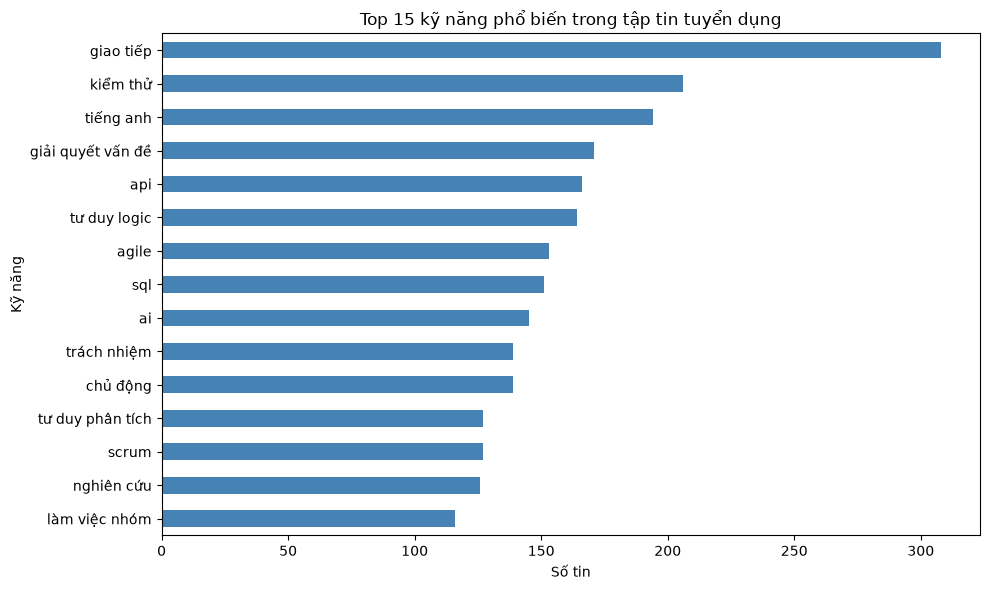

In [32]:
fig, ax = plt.subplots(figsize=(10, 6))

top15.sort_values().plot(
    kind="barh",
    ax=ax,
    color="steelblue"
)

ax.set_title("Top 15 kỹ năng phổ biến trong tập tin tuyển dụng")
ax.set_xlabel("Số tin")
ax.set_ylabel("Kỹ năng")

plt.tight_layout()

plt.savefig(
    figures_dir / "top15_skills.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Nhận xét

Sau chuẩn hóa và lọc nhãn chung, giao tiếp xuất hiện nhiều nhất với 308 tin (35,69%). Các kỹ năng chuyên môn xuất hiện nhiều gồm kiểm thử, API, Agile, SQL và AI. Tư duy logic được nhận diện trong 164 tin (19,00%) thông qua nhãn kỹ năng có sẵn và các cụm diễn đạt rõ ràng trong yêu cầu tuyển dụng.


In [33]:
display(df_eda["salary_type"].value_counts())

salary_type
Thỏa thuận      428
Khoảng lương    338
Cận trên         91
Cận dưới          6
Name: count, dtype: int64

In [34]:
salary_df = df_eda.dropna(
    subset=["salary_min", "salary_max"]
).copy()

salary_df["salary_mid_million"] = (
    (salary_df["salary_min"] + salary_df["salary_max"])
    / 2
    / 1_000_000
)

print("Tổng số tin:", len(df_eda))
print("Số tin đủ hai cận lương:", len(salary_df))

display(
    salary_df[
        ["salary_min", "salary_max", "salary_mid_million"]
    ].head()
)

Tổng số tin: 863
Số tin đủ hai cận lương: 338


,salary_min,salary_max,salary_mid_million
0,10000000.0,20000000.0,15.0
2,10000000.0,15000000.0,12.5
6,7000000.0,20000000.0,13.5
8,18000000.0,24000000.0,21.0
9,7000000.0,20000000.0,13.5


In [35]:
display(salary_df["salary_mid_million"].describe())

count    338.000000
mean      23.229734
std       12.022325
min        1.500000
25%       15.000000
50%       21.000000
75%       30.000000
max       67.500000
Name: salary_mid_million, dtype: float64

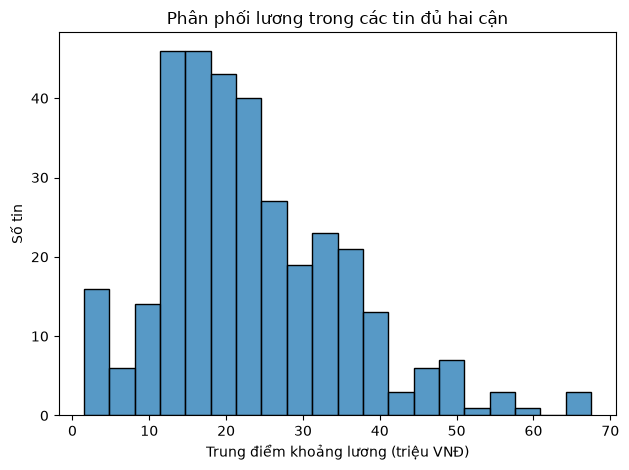

In [36]:
sns.histplot(
    data=salary_df,
    x="salary_mid_million",
    bins=20
)

plt.xlabel("Trung điểm khoảng lương (triệu VNĐ)")
plt.ylabel("Số tin")
plt.title("Phân phối lương trong các tin đủ hai cận")
plt.tight_layout()
plt.savefig(
    figures_dir / "salary_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### Nhận xét phân phối lương

Phân tích sử dụng 338/863 tin có đủ hai cận lương,
tương đương khoảng 39,2% dữ liệu. Nhóm dùng trung điểm
khoảng lương đăng tuyển làm giá trị đại diện và quy đổi
sang triệu VNĐ.

Trung bình trung điểm khoảng lương là 23,23 triệu,
trung vị là 21 triệu. Biểu đồ có đuôi kéo về phía
các mức lương cao, phù hợp với việc trung bình lớn hơn
trung vị.

Tin thỏa thuận và tin chỉ có một cận không được dùng
để tính trung điểm. Kết quả không đại diện cho toàn bộ
tin tuyển dụng và không phải lương thực nhận.

In [37]:
display(df_eda["level_raw"].value_counts())

display(
    df_eda[["job_title", "level_raw"]].head(20)
)

level_raw
Nhân viên             547
Trưởng nhóm           202
Trưởng/Phó phòng       40
Thực tập sinh          37
Quản lý / Giám sát     34
Giám đốc                3
Name: count, dtype: int64

,job_title,level_raw
0,Chuyên Viên Kiểm Tra Chất Lượng Phần Mềm - Tester,Nhân viên
1,Quản Lý Dự Án Hạ Tầng Facilities - PM,Nhân viên
2,Chuyên Viên Kiểm Thử Phần Mềm,Nhân viên
3,Fullstack Developer,Nhân viên
4,QA Engineer (Pre-Deployment Codebase Testing),Nhân viên
5,Fullstack Developer ( NodeJS / PHP /Go) – E-Co...,Nhân viên
6,Nhân Viên Tư Vấn Triển Khai Phần Mềm Website (...,Nhân viên
7,Java Developer,Nhân viên
8,Tester (Manual/Automation) – Thu Nhập 18-24 Tr...,Nhân viên
9,Nhân Viên Tư Vấn Triển Khai Phần Mềm Website (...,Nhân viên


In [38]:
import re

def get_seniority(row):
    for field in ["level_raw", "job_title"]:
        text = str(row[field]).lower()

        matches = re.findall(
            r"\b(fresher|junior|middle|senior|lead)\b",
            text
        )

        levels = set(matches)

        if len(levels) == 1:
            return next(iter(levels)).capitalize()

        if len(levels) > 1:
            return "Chưa xác định"

    return "Chưa xác định"

df_eda["seniority"] = df_eda.apply(
    get_seniority,
    axis=1
)

display(df_eda["seniority"].value_counts())

seniority
Chưa xác định    707
Lead              63
Senior            55
Junior            13
Middle            13
Fresher           12
Name: count, dtype: int64

In [39]:
salary_df = df_eda.dropna(
    subset=["salary_min", "salary_max"]
).copy()

salary_df["salary_mid_million"] = (
    (salary_df["salary_min"] + salary_df["salary_max"])
    / 2
    / 1_000_000
)

level_salary = salary_df[
    salary_df["seniority"] != "Chưa xác định"
].copy()

display(
    level_salary.groupby("seniority")["salary_mid_million"]
    .agg(["count", "mean", "median"])
)

,count,mean,median
seniority,,,
Fresher,7,12.071429,11.50
Junior,8,14.062500,14.75
Lead,24,33.312500,32.25
Middle,4,25.250000,23.75
Senior,19,33.868421,36.00


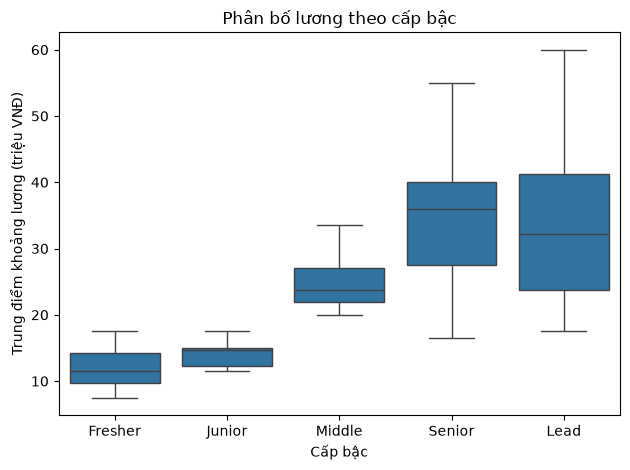

In [40]:
if level_salary.empty:
    print("Chưa có tin vừa xác định cấp bậc vừa đủ hai cận lương.")
else:
    sns.boxplot(
        data=level_salary,
        x="seniority",
        y="salary_mid_million",
        order=["Fresher", "Junior", "Middle", "Senior", "Lead"]
    )

    plt.xlabel("Cấp bậc")
    plt.ylabel("Trung điểm khoảng lương (triệu VNĐ)")
    plt.title("Phân bố lương theo cấp bậc")
    plt.tight_layout()
    plt.savefig(
        figures_dir / "salary_by_seniority.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

### Nhận xét lương theo cấp bậc

Có 156 tin nhận diện được cấp bậc; trong đó 62 tin
có đủ hai cận lương để phân tích.

Trung vị trung điểm khoảng lương lần lượt là:
Fresher 11,50 triệu; Junior 14,75 triệu;
Middle 23,75 triệu; Senior 36 triệu; Lead 32,25 triệu.

Kết quả cho thấy khác biệt giữa các nhóm trong mẫu,
nhưng chưa đủ để kết luận Senior luôn được trả cao hơn
Lead. Số mẫu giữa các nhóm không đồng đều, đặc biệt
Middle chỉ có 4 tin. Các tin chưa xác định cấp bậc
không được tự gán từ nhãn chung “Nhân viên”.

In [41]:
display(df_eda["province"].value_counts())

province
Hà Nội         627
Hồ Chí Minh    178
Đà Nẵng         20
Bắc Ninh         7
Đồng Nai         6
Thái Nguyên      4
Khánh Hòa        4
Hải Phòng        3
Tây Ninh         3
Quảng Trị        2
Nghệ An          1
Phú Thọ          1
Hưng Yên         1
Gia Lai          1
Lâm Đồng         1
Vĩnh Long        1
Quảng Ninh       1
Ninh Bình        1
Đắk Lắk          1
Name: count, dtype: int64

In [42]:
cities = ["Hà Nội", "Hồ Chí Minh", "Đà Nẵng"]

city_df = df_eda[
    df_eda["province"].isin(cities)
].copy()

province
Hà Nội         627
Hồ Chí Minh    178
Đà Nẵng         20
Name: count, dtype: int64

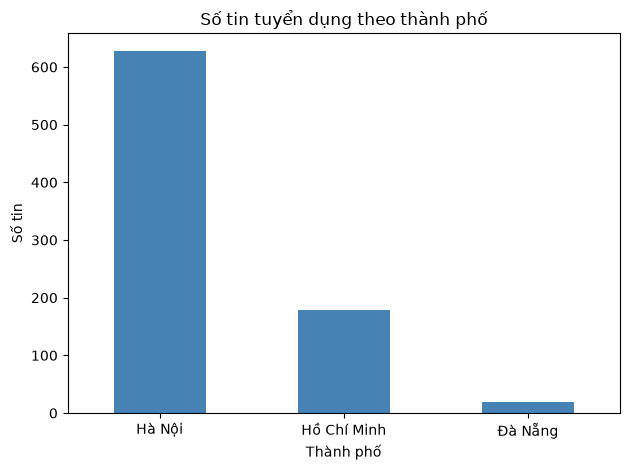

In [43]:
city_counts = (
    city_df["province"]
    .value_counts()
    .reindex(cities, fill_value=0)
)

display(city_counts)

city_counts.plot(kind="bar", color="steelblue")

plt.xlabel("Thành phố")
plt.ylabel("Số tin")
plt.title("Số tin tuyển dụng theo thành phố")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    figures_dir / "jobs_by_city.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

,count,mean,median
province,,,
Hà Nội,257,24.089300,22.0
Hồ Chí Minh,61,20.839344,19.5
Đà Nẵng,4,22.250000,14.5


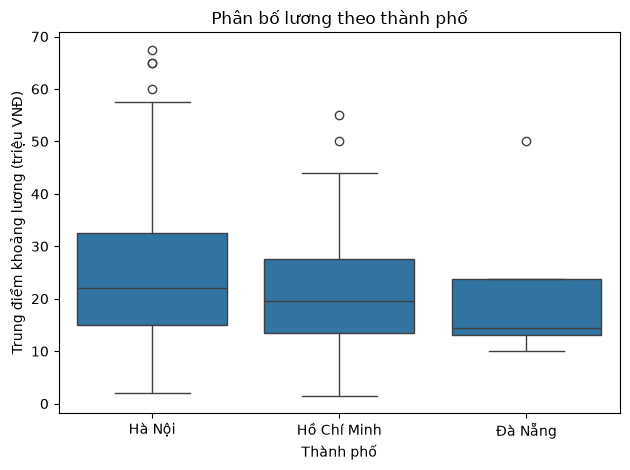

In [44]:
city_salary = salary_df[
    salary_df["province"].isin(cities)
].copy()

display(
    city_salary.groupby("province")["salary_mid_million"]
    .agg(["count", "mean", "median"])
)

if not city_salary.empty:
    sns.boxplot(
        data=city_salary,
        x="province",
        y="salary_mid_million",
        order=cities
    )

    plt.xlabel("Thành phố")
    plt.ylabel("Trung điểm khoảng lương (triệu VNĐ)")
    plt.title("Phân bố lương theo thành phố")
    plt.tight_layout()
    plt.savefig(
        figures_dir / "salary_by_city.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

### Nhận xét so sánh khu vực

Trong mẫu thu thập, Hà Nội có 627 tin, TP.HCM có
178 tin và Đà Nẵng có 20 tin.

Số tin đủ hai cận lương lần lượt là 257, 61 và 4.
Trung vị trung điểm khoảng lương tương ứng là
22; 19,5 và 14,5 triệu VNĐ.

Đà Nẵng có rất ít tin công khai đủ khoảng lương,
nên kết quả chỉ mang tính mô tả mẫu. Chênh lệch lương
có thể liên quan đến cơ cấu nghề, cấp bậc và cách
thu thập dữ liệu; không suy rộng trực tiếp thành
chênh lệch của toàn thị trường.

In [45]:
display(df_eda["experience"].value_counts(dropna=False))
display(df_eda["salary_type"].value_counts(dropna=False))

experience
3 năm            215
2 năm            213
1 năm            144
5 năm             77
Không yêu cầu     62
4 năm             57
Trên 5 năm        55
Dưới 1 năm        40
Name: count, dtype: int64

salary_type
Thỏa thuận      428
Khoảng lương    338
Cận trên         91
Cận dưới          6
Name: count, dtype: int64

### Phân bố lương theo kinh nghiệm yêu cầu

,count,mean,median
experience,,,
Dưới 1 năm,25,13.63,13.50
1 năm,71,16.07,15.00
2 năm,85,22.18,21.00
3 năm,76,29.53,29.25
4 năm,16,35.28,34.25
5 năm,24,36.21,35.00
Trên 5 năm,11,48.50,50.00
Không yêu cầu,30,9.12,7.00


Số tin được dùng: 338


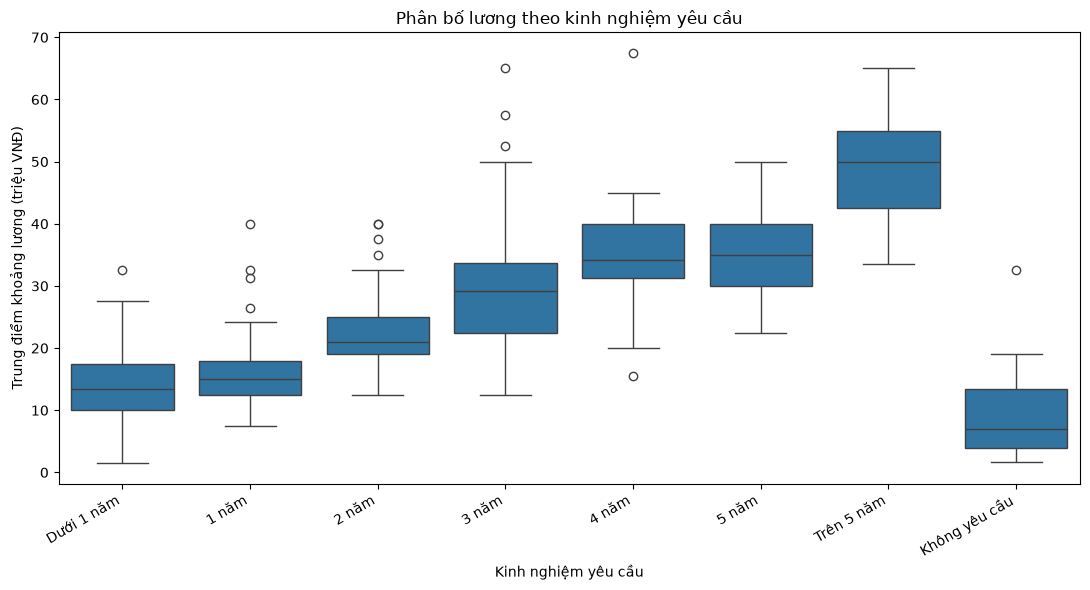

In [46]:
experience_order = [
    "Dưới 1 năm",
    "1 năm",
    "2 năm",
    "3 năm",
    "4 năm",
    "5 năm",
    "Trên 5 năm",
    "Không yêu cầu"
]

experience_salary_summary = (
    salary_df.groupby("experience")["salary_mid_million"]
    .agg(["count", "mean", "median"])
    .reindex(experience_order)
)

display(experience_salary_summary.round(2))

print(
    "Số tin được dùng:",
    experience_salary_summary["count"].sum()
)

if salary_df.empty:
    print("Chưa có tin đủ hai cận lương để vẽ.")
else:
    fig, ax = plt.subplots(figsize=(11, 6))

    sns.boxplot(
        data=salary_df,
        x="experience",
        y="salary_mid_million",
        order=experience_order,
        ax=ax
    )

    ax.set_title("Phân bố lương theo kinh nghiệm yêu cầu")
    ax.set_xlabel("Kinh nghiệm yêu cầu")
    ax.set_ylabel("Trung điểm khoảng lương (triệu VNĐ)")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    fig.savefig(
        figures_dir / "salary_by_experience.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

Phân tích sử dụng 338 tin có đủ hai cận lương.
Trung vị trung điểm khoảng lương tăng từ 13,5 triệu ở nhóm
dưới 1 năm lên 21 triệu ở nhóm 2 năm, 29,25 triệu ở nhóm
3 năm và 50 triệu ở nhóm trên 5 năm.

Trong mẫu này, các nhóm yêu cầu nhiều kinh nghiệm hơn có
trung vị lương cao hơn. Tuy nhiên, số tin giữa các nhóm
không đều. Nhóm trên 5 năm chỉ có 11 tin đủ khoảng lương,
nên cần thận trọng khi so sánh.

Nhóm không yêu cầu kinh nghiệm có trung vị 7 triệu.
Kết quả dùng trung điểm khoảng lương đăng tuyển, không phải
lương thực nhận và không chứng minh kinh nghiệm là yếu tố
duy nhất quyết định mức lương.

### Số tin tuyển dụng theo kinh nghiệm yêu cầu

,so_tin
experience,
Dưới 1 năm,40
1 năm,144
2 năm,213
3 năm,215
4 năm,57
5 năm,77
Trên 5 năm,55
Không yêu cầu,62


Tổng số tin: 863


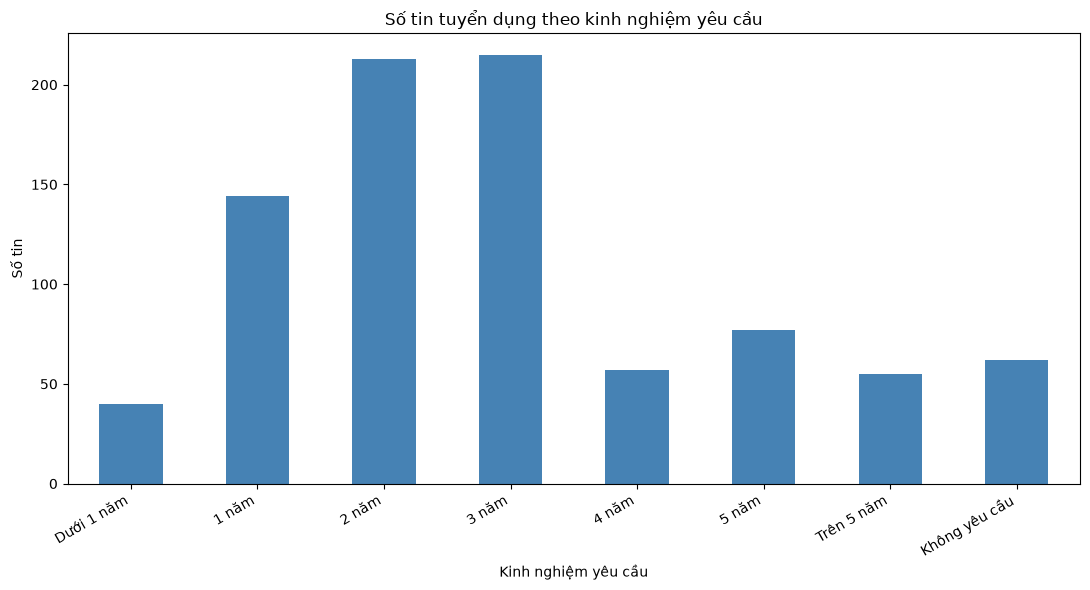

In [47]:
experience_counts = (
    df_eda["experience"]
    .value_counts()
    .reindex(experience_order, fill_value=0)
)

display(experience_counts.to_frame(name="so_tin"))
print("Tổng số tin:", experience_counts.sum())

fig, ax = plt.subplots(figsize=(11, 6))

experience_counts.plot(
    kind="bar",
    ax=ax,
    color="steelblue"
)

ax.set_title("Số tin tuyển dụng theo kinh nghiệm yêu cầu")
ax.set_xlabel("Kinh nghiệm yêu cầu")
ax.set_ylabel("Số tin")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

fig.savefig(
    figures_dir / "jobs_by_experience.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Nhóm yêu cầu 3 năm kinh nghiệm có nhiều tin nhất với 215 tin,
tiếp theo là nhóm 2 năm với 213 tin. Hai nhóm này chiếm khoảng
49,6% số tin trong mẫu.

Có 62 tin không yêu cầu kinh nghiệm. Đây là cách ghi yêu cầu
của nhà tuyển dụng, không có nghĩa các vị trí này chỉ tuyển
người chưa có kinh nghiệm.

### So sánh cách công bố lương giữa các thành phố

salary_type,Khoảng lương,Thỏa thuận,Cận trên,Cận dưới
province,,,,
Hà Nội,257,280,85,5
Hồ Chí Minh,61,111,5,1
Đà Nẵng,4,15,1,0


salary_type,Khoảng lương,Thỏa thuận,Cận trên,Cận dưới
province,,,,
Hà Nội,40.99,44.66,13.56,0.80
Hồ Chí Minh,34.27,62.36,2.81,0.56
Đà Nẵng,20.00,75.00,5.00,0.00


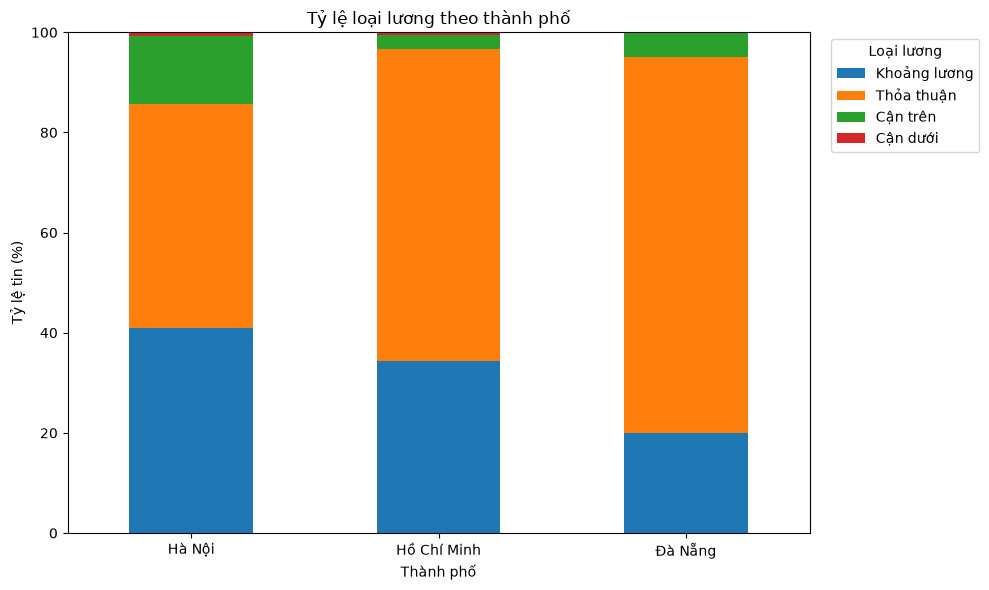

In [48]:
salary_type_order = [
    "Khoảng lương",
    "Thỏa thuận",
    "Cận trên",
    "Cận dưới"
]

# Đếm số tin theo thành phố và loại lương
salary_type_counts = pd.crosstab(
    city_df["province"],
    city_df["salary_type"]
).reindex(
    index=cities,
    columns=salary_type_order,
    fill_value=0
)

# Chuyển số lượng thành tỷ lệ trong từng thành phố
salary_type_percent = (
    salary_type_counts
    .div(salary_type_counts.sum(axis=1), axis=0)
    .mul(100)
)

display(salary_type_counts)
display(salary_type_percent.round(2))

fig, ax = plt.subplots(figsize=(10, 6))

salary_type_percent.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title("Tỷ lệ loại lương theo thành phố")
ax.set_xlabel("Thành phố")
ax.set_ylabel("Tỷ lệ tin (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Loại lương",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()

fig.savefig(
    figures_dir / "salary_type_by_city.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Lương thỏa thuận chiếm 44,66% số tin tại Hà Nội,
62,36% tại TP.HCM và 75% tại Đà Nẵng.

Tỷ lệ tin công bố đủ khoảng lương lần lượt là 40,99%,
34,27% và 20%. Vì vậy, phần so sánh mức lương trước đó
chỉ sử dụng một phần số tin thu thập ở mỗi thành phố.

Đà Nẵng chỉ có 20 tin trong mẫu, trong đó 4 tin đủ hai
cận lương. Các tỷ lệ này mô tả mẫu thu thập, chưa đủ để
kết luận về toàn bộ thị trường tuyển dụng tại mỗi nơi.

## Bước 2.3: Gom cụm dữ liệu tuyển dụng

Tạo ma trận kỹ năng dùng chung cho gom cụm và luật kết hợp. Mỗi hàng là một tin, mỗi kỹ năng được biểu diễn bằng 0/1.

In [49]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
    fpgrowth,
    association_rules
)

transactions = df_eda["skills_analysis"].tolist()

print("Số giao dịch:", len(transactions))
print("Ba giỏ đầu:")
print(transactions[:3])

Số giao dịch: 863
Ba giỏ đầu:
[['bug tracking tools (jira, bugzilla)', 'kiến thức về kiểm thử phần mềm', 'kỹ năng viết test case', 'test automation (selenium, appium,...)', 'test management tools (testrail, zephyr...)', 'tư duy logic'], ['an ninh mạng', 'analysis', 'data', 'documentation', 'giao tiếp', 'giải quyết vấn đề', 'networking', 'payment', 'project documentation', 'project execution', 'project management', 'tư duy logic'], ['exploratory testing', 'git', 'intellij idea', 'java', 'javascript', 'kiểm thử phần mềm black box', 'non-ui testing', 'postman/api testing', 'risk-based testing', 'tester']]


In [50]:
te = TransactionEncoder()

encoded = te.fit(transactions).transform(transactions)

basket = pd.DataFrame(
    encoded,
    columns=te.columns_,
    index=df_eda.index
)

print("Kích thước ma trận:", basket.shape)
display(basket.head())

Kích thước ma trận: (863, 2120)


,.net,".net (c#, asp.net core, entity framework)",.net 6+,.net 8,.net core,.net core (c#),.net framework,.net framework core,.net-reactjs,24/7 shift rotation,...,ưu tiên hóa các tính năng,ảo hóa,ảo hóa proxmox,ẩm thực,ứng dụng ai,ứng dụng ai tools,ứng dụng ai trong quản trị dự án,ứng dụng ai/ai assistant,ứng dụng ai/genai,ứng dụng công cụ ai
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Chuẩn bị dữ liệu gom cụm

Chỉ dùng các tin có ít nhất một kỹ năng được nhận diện; không đưa lương hoặc cấp bậc vào K-Means.

In [51]:
tables_dir = PROJECT_ROOT / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
assert basket.index.equals(df_eda.index)
X_cluster = basket.loc[basket.any(axis=1)].astype(int)
print("Tin dùng để gom cụm:", len(X_cluster))
print("Tin không phát hiện kỹ năng:", len(basket) - len(X_cluster))

Tin dùng để gom cụm: 862
Tin không phát hiện kỹ năng: 1


### Nhận xét

862/863 tin có ít nhất một kỹ năng được đưa vào gom cụm; 1 tin còn lại giữ nhãn -1. Không tự điền kỹ năng để tạo cụm cho các tin này.

### Khảo sát số cụm

Chạy K = 2–8 trên cùng đầu vào và seed; lập bảng Elbow/Inertia và Silhouette.

In [52]:
cluster_models, k_rows = {}, []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(X_cluster)
    cluster_models[k] = model
    k_rows.append({"K": k, "inertia": model.inertia_,
                   "silhouette": silhouette_score(X_cluster, labels)})
k_selection = pd.DataFrame(k_rows)
display(k_selection)
best_k = int(k_selection.loc[k_selection["silhouette"].idxmax(), "K"])
print("K gợi ý theo Silhouette:", best_k)

,K,inertia,silhouette
0,2,14658.652195,0.153733
1,3,14184.772190,0.131930
2,4,13914.362118,0.131930
3,5,13880.171007,0.144249
4,6,13696.653337,0.103632
5,7,13525.852060,0.101814
6,8,13397.882884,0.086832


K gợi ý theo Silhouette: 2


### Nhận xét

Phương án gợi ý là K = 2, có Silhouette 0,1537 cao nhất trong các K đã thử. Điểm còn thấp, cho thấy các cụm chồng lấn; không coi số cụm này là số nghề đúng trong thị trường.


### Biểu đồ chọn K

Đọc Elbow cùng Silhouette để đánh giá mức độ phân tách.

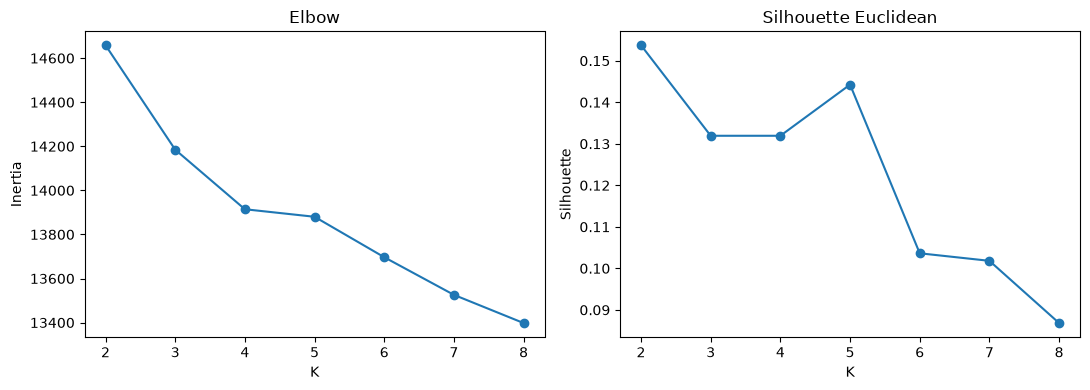

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_selection["K"], k_selection["inertia"], "o-")
axes[0].set(xlabel="K", ylabel="Inertia", title="Elbow")
axes[1].plot(k_selection["K"], k_selection["silhouette"], "o-")
axes[1].set(xlabel="K", ylabel="Silhouette", title="Silhouette Euclidean")
plt.tight_layout()
plt.savefig(figures_dir / "k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

### Nhận xét

Inertia giảm khi tăng K, nhưng Elbow chưa tạo điểm gãy mạnh. Nhóm dùng Silhouette cùng biểu đồ để chọn phương án và giữ giới hạn phân tách của kết quả.

### Chân dung các cụm

Thống kê số tin, ba kỹ năng phổ biến và gán tên mô tả từ các kỹ năng của mỗi cụm.

In [54]:
cluster_labels = pd.Series(cluster_models[best_k].labels_, index=X_cluster.index)
cluster_assignment = df_eda[["source_url", "job_title"]].copy()
cluster_assignment["cluster"] = -1
cluster_assignment.loc[X_cluster.index, "cluster"] = cluster_labels
profile_rows = []
for c in sorted(cluster_labels.unique()):
    rates = X_cluster.loc[cluster_labels.eq(c)].mean().nlargest(3)
    profile_rows.append({"cluster": c, "n_jobs": int(cluster_labels.eq(c).sum()),
                         "profile_name": "Nổi bật: " + ", ".join(rates.index),
                         "top3_skills": "; ".join(f"{s}: {v:.0%}" for s, v in rates.items())})
cluster_summary = pd.DataFrame(profile_rows)
display(cluster_summary)
k_selection.to_csv(tables_dir / "k_selection.csv", index=False)
cluster_summary.to_csv(tables_dir / "cluster_summary.csv", index=False)
cluster_assignment.to_csv(tables_dir / "cluster_assignments.csv", index=False)

,cluster,n_jobs,profile_name,top3_skills
0,0,293,"Nổi bật: giao tiếp, kiểm thử, api",giao tiếp: 59%; kiểm thử: 51%; api: 48%
1,1,569,"Nổi bật: giao tiếp, tư duy logic, giải quyết v...",giao tiếp: 24%; tư duy logic: 17%; giải quyết ...


### Nhận xét

Cụm 0 có 293 tin, nổi bật: giao tiếp, kiểm thử, api. Cụm 1 có 569 tin, nổi bật: giao tiếp, tư duy logic, giải quyết vấn đề. Các cụm là cấu hình kỹ năng trong mẫu; có thể chịu ảnh hưởng của tag/fallback và mức chi tiết JD, chưa tách thành các nghề rõ ràng.


## Bước 2.4: Khai phá luật kết hợp kỹ năng

Sử dụng đúng ma trận kỹ năng ở bước 2.3.

In [55]:
print(
    "Các từ chung còn trong ma trận:",
    sorted(set(basket.columns) & generic_terms)
)

Các từ chung còn trong ma trận: []


In [56]:
MIN_SUPPORT = 0.05

frequent_itemsets = fpgrowth(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

frequent_itemsets["so_ky_nang"] = (
    frequent_itemsets["itemsets"].apply(len)
)

display(
    frequent_itemsets.sort_values(
        "support",
        ascending=False
    ).head(20)
)

,support,itemsets,so_ky_nang
1,0.356895,frozenset({giao tiếp}),1
8,0.238702,frozenset({kiểm thử}),1
57,0.224797,frozenset({tiếng anh}),1
2,0.198146,frozenset({giải quyết vấn đề}),1
9,0.192352,frozenset({api}),1
0,0.190035,frozenset({tư duy logic}),1
52,0.177289,frozenset({agile}),1
10,0.174971,frozenset({sql}),1
11,0.168019,frozenset({ai}),1
12,0.161066,frozenset({trách nhiệm}),1


In [57]:
display(
    frequent_itemsets[
        frequent_itemsets["so_ky_nang"] >= 2
    ].sort_values("support", ascending=False).head(20)
)

,support,itemsets,so_ky_nang
181,0.140209,"frozenset({agile, scrum})",2
194,0.139050,"frozenset({tiếng anh, giao tiếp})",2
92,0.133256,"frozenset({giải quyết vấn đề, giao tiếp})",2
103,0.122827,"frozenset({kiểm thử, giao tiếp})",2
179,0.104287,"frozenset({agile, giao tiếp})",2
104,0.101970,"frozenset({api, kiểm thử})",2
105,0.097335,"frozenset({api, giao tiếp})",2
184,0.090382,"frozenset({scrum, giao tiếp})",2
119,0.089224,"frozenset({chủ động, trách nhiệm})",2
155,0.089224,"frozenset({giao tiếp, tư duy phân tích})",2


In [58]:
def make_rules(itemsets, n_transactions):
    has_pairs = itemsets["itemsets"].apply(len).ge(2).any()

    if not has_pairs:
        return pd.DataFrame(columns=[
            "antecedents", "consequents",
            "antecedent support", "consequent support",
            "support", "confidence", "lift",
            "leverage", "conviction"
        ])

    return association_rules(
        itemsets,
        num_itemsets=n_transactions,
        metric="confidence",
        min_threshold=0.60
    )

rules = make_rules(frequent_itemsets, len(basket))
print("Số luật:", len(rules))
display(rules.head())

Số luật: 55


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({giải quyết vấn đề}),frozenset({giao tiếp}),0.198146,0.356895,0.133256,0.672515,1.884351,1.0,0.062539,1.963768,0.585285,0.315934,0.490775,0.522946
1,"frozenset({giải quyết vấn đề, tiếng anh})",frozenset({giao tiếp}),0.079954,0.356895,0.061414,0.768116,2.152221,1.0,0.032879,2.773392,0.581888,0.163580,0.639431,0.470097
2,"frozenset({api, sql})",frozenset({kiểm thử}),0.083430,0.238702,0.055620,0.666667,2.792880,1.0,0.035705,2.283893,0.700379,0.208696,0.562151,0.449838
3,"frozenset({sql, kiểm thử})",frozenset({api}),0.076477,0.192352,0.055620,0.727273,3.780942,1.0,0.040909,2.961375,0.796424,0.260870,0.662319,0.508215
4,"frozenset({chủ động, giao tiếp})",frozenset({trách nhiệm}),0.082271,0.161066,0.052144,0.633803,3.935049,1.0,0.038893,2.290935,0.812738,0.272727,0.563497,0.478772


In [59]:
support_grid = [0.25, 0.18, 0.12, 0.08, 0.05]
records = []

for support in support_grid:
    itemsets = fpgrowth(
        basket,
        min_support=support,
        use_colnames=True
    )

    current_rules = make_rules(itemsets, len(basket))

    strong = current_rules[
        (current_rules["confidence"] >= 0.65)
        & (current_rules["lift"] > 1.2)
    ]

    records.append({
        "min_support": support,
        "so_tap_pho_bien": len(itemsets),
        "so_luat": len(current_rules),
        "so_luat_sau_loc": len(strong)
    })

sensitivity = pd.DataFrame(records)
display(sensitivity)

,min_support,so_tap_pho_bien,so_luat,so_luat_sau_loc
0,0.25,1,0,0
1,0.18,6,0,0
2,0.12,26,4,3
3,0.08,63,12,6
4,0.05,227,55,37


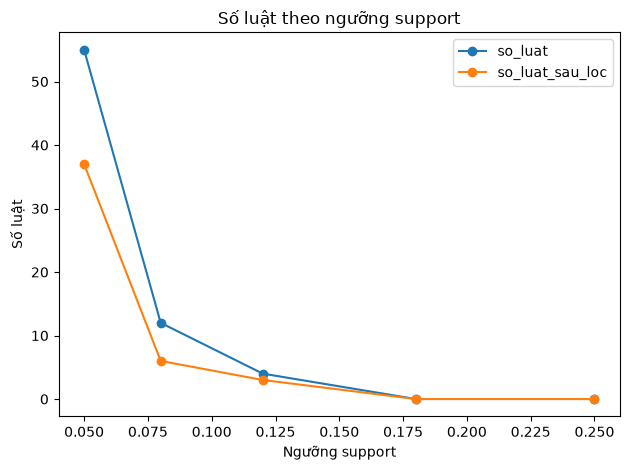

In [60]:
sensitivity.plot(
    x="min_support",
    y=["so_luat", "so_luat_sau_loc"],
    marker="o"
)

plt.xlabel("Ngưỡng support")
plt.ylabel("Số luật")
plt.title("Số luật theo ngưỡng support")
plt.tight_layout()
plt.savefig(
    figures_dir / "support_sensitivity.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### Lựa chọn ngưỡng phân tích

Nhóm chọn support 0.05, confidence tối thiểu 0.65
và lift lớn hơn 1.2 cho phiên bản dữ liệu hiện tại.

Với 863 tin, support 0.05 yêu cầu một tổ hợp xuất hiện
trong ít nhất 44 tin. Ngưỡng này giữ được các tổ hợp
công nghệ như Kubernetes–Docker và Linux–Docker
bị bỏ qua tại ngưỡng 0.08.

Các luật tiếp tục được kiểm tra bằng Conviction,
loại bỏ luật dư thừa và đánh giá ý nghĩa trong
bối cảnh tuyển dụng.

Kết quả đang sử dụng dữ liệu kỹ năng được nhóm
tiếp tục rà soát. Khi đầu vào thay đổi, các bước
khảo sát và phân tích sẽ được chạy lại.

In [61]:
CHOSEN_SUPPORT = 0.05
CHOSEN_CONFIDENCE = 0.65
CHOSEN_LIFT = 1.2

frequent_itemsets = fpgrowth(
    basket,
    min_support=CHOSEN_SUPPORT,
    use_colnames=True
)

rules = make_rules(
    frequent_itemsets,
    len(basket)
)

strong_rules = rules[
    (rules["confidence"] >= CHOSEN_CONFIDENCE)
    & (rules["lift"] > CHOSEN_LIFT)
].copy()

print("Support được chọn:", CHOSEN_SUPPORT)
print("Số tập phổ biến:", len(frequent_itemsets))
print("Số luật có Confidence ≥ 0.60:", len(rules))
print("Số luật sau lọc chỉ số:", len(strong_rules))

Support được chọn: 0.05
Số tập phổ biến: 227
Số luật có Confidence ≥ 0.60: 55
Số luật sau lọc chỉ số: 37


In [62]:
def readable_rules(table):
    result = table.copy()

    result["ve_trai"] = result["antecedents"].apply(
        lambda items: ", ".join(sorted(items))
    )

    result["ve_phai"] = result["consequents"].apply(
        lambda items: ", ".join(sorted(items))
    )

    result["so_tin_ho_tro"] = (
        result["support"] * len(basket)
    ).round().astype(int)

    return result[[
        "ve_trai", "ve_phai", "so_tin_ho_tro",
        "support", "confidence", "lift",
        "leverage", "conviction"
    ]]

display(
    readable_rules(strong_rules)
    .sort_values("lift", ascending=False)
    .head(20)
)

,ve_trai,ve_phai,so_tin_ho_tro,support,confidence,lift,leverage,conviction
51,ui/ux,ux,58,0.067207,0.840580,10.827169,0.061000,5.785737
52,ux,ui/ux,58,0.067207,0.865672,10.827169,0.061000,6.849234
53,confluence,jira,44,0.050985,1.000000,8.544554,0.045018,inf
47,ngân hàng,tài chính,65,0.075319,0.783133,7.593746,0.065400,4.135574
48,tài chính,ngân hàng,65,0.075319,0.730337,7.593746,0.065400,3.351680
17,"ci/cd, kubernetes",docker,50,0.057937,0.862069,7.085386,0.049760,6.367903
16,"ci/cd, docker",kubernetes,50,0.057937,0.714286,6.773940,0.049384,3.130939
43,"agile, jira",scrum,50,0.057937,0.925926,6.291922,0.048729,11.513326
21,aws,cloud,48,0.055620,0.716418,6.245138,0.046714,3.121791
13,kubernetes,docker,68,0.078795,0.747253,6.141706,0.065965,3.475137


In [63]:
trap_rules = rules[
    (rules["confidence"] >= 0.65)
    & (rules["lift"] <= 1)
].copy()

display(readable_rules(trap_rules).head(10))

,ve_trai,ve_phai,so_tin_ho_tro,support,confidence,lift,leverage,conviction


### Kiểm tra bẫy độ tin cậy

Tại cấu hình đang xét, không tìm thấy luật đồng thời
có confidence từ 0.65 và lift không vượt quá 1.

Kết quả này không có nghĩa mọi luật đều hữu ích.
Các luật vẫn cần được xem xét về ý nghĩa, nhãn chồng lấn
và số tin hỗ trợ.

In [64]:
redundant = []

for i, rule_i in strong_rules.iterrows():
    for j, rule_j in strong_rules.iterrows():
        same_consequent = (
            rule_i["consequents"] == rule_j["consequents"]
        )

        shorter_antecedent = (
            rule_j["antecedents"] < rule_i["antecedents"]
        )

        no_improvement = (
            rule_i["confidence"]
            <= rule_j["confidence"] + 1e-6
        )

        if same_consequent and shorter_antecedent and no_improvement:
            redundant.append(i)
            break

pruned_rules = strong_rules.drop(index=redundant)

print("Trước lọc dư thừa:", len(strong_rules))
print("Sau lọc dư thừa:", len(pruned_rules))

display(readable_rules(pruned_rules).head(10))

Trước lọc dư thừa: 37
Sau lọc dư thừa: 34


,ve_trai,ve_phai,so_tin_ho_tro,support,confidence,lift,leverage,conviction
0,giải quyết vấn đề,giao tiếp,115,0.133256,0.672515,1.884351,0.062539,1.963768
1,"giải quyết vấn đề, tiếng anh",giao tiếp,53,0.061414,0.768116,2.152221,0.032879,2.773392
2,"api, sql",kiểm thử,48,0.055620,0.666667,2.792880,0.035705,2.283893
3,"kiểm thử, sql",api,48,0.055620,0.727273,3.780942,0.040909,2.961375
6,docker,ci/cd,70,0.081112,0.666667,5.136905,0.065322,2.610660
8,web,api,67,0.077636,0.656863,3.414895,0.054902,2.353716
9,"api, web",kiểm thử,44,0.050985,0.656716,2.751195,0.032453,2.217694
10,"kiểm thử, web",api,44,0.050985,0.785714,4.084768,0.038503,3.769023
13,kubernetes,docker,68,0.078795,0.747253,6.141706,0.065965,3.475137
15,"docker, kubernetes",ci/cd,50,0.057937,0.735294,5.665704,0.047711,3.287498


In [65]:
final_rules = readable_rules(pruned_rules).sort_values(
    ["lift", "confidence", "support"],
    ascending=False
).reset_index(drop=True)

print("Số giao dịch:", len(basket))
print("Support:", CHOSEN_SUPPORT)
print("Confidence tối thiểu:", CHOSEN_CONFIDENCE)
print("Lift lớn hơn:", CHOSEN_LIFT)

print("Số luật sau lọc chỉ số:", len(strong_rules))
print("Số luật dư thừa bị loại:", len(redundant))
print("Số luật cuối cùng:", len(final_rules))

display(final_rules)

Số giao dịch: 863
Support: 0.05
Confidence tối thiểu: 0.65
Lift lớn hơn: 1.2
Số luật sau lọc chỉ số: 37
Số luật dư thừa bị loại: 3
Số luật cuối cùng: 34


,ve_trai,ve_phai,so_tin_ho_tro,support,confidence,lift,leverage,conviction
0,ui/ux,ux,58,0.067207,0.840580,10.827169,0.061000,5.785737
1,ux,ui/ux,58,0.067207,0.865672,10.827169,0.061000,6.849234
2,confluence,jira,44,0.050985,1.000000,8.544554,0.045018,inf
3,ngân hàng,tài chính,65,0.075319,0.783133,7.593746,0.065400,4.135574
4,tài chính,ngân hàng,65,0.075319,0.730337,7.593746,0.065400,3.351680
5,"ci/cd, kubernetes",docker,50,0.057937,0.862069,7.085386,0.049760,6.367903
6,"ci/cd, docker",kubernetes,50,0.057937,0.714286,6.773940,0.049384,3.130939
7,"agile, jira",scrum,50,0.057937,0.925926,6.291922,0.048729,11.513326
8,aws,cloud,48,0.055620,0.716418,6.245138,0.046714,3.121791
9,kubernetes,docker,68,0.078795,0.747253,6.141706,0.065965,3.475137


In [66]:
print("Các luật bị loại vì dư thừa:")

display(
    readable_rules(
        strong_rules.loc[redundant]
    )
)

Các luật bị loại vì dư thừa:


,ve_trai,ve_phai,so_tin_ho_tro,support,confidence,lift,leverage,conviction
34,"api, scrum",agile,44,0.050985,0.936170,5.280490,0.041330,12.889146
37,"giao tiếp, scrum",agile,73,0.084589,0.935897,5.278951,0.068565,12.834299
44,"jira, scrum",agile,50,0.057937,0.943396,5.321248,0.047049,14.534569


Luật {Scrum} ⇒ {Agile} có confidence khoảng 95,28%. Khi thêm các điều kiện phụ vào vế trái như Jira (confidence đạt 94,34%), API (confidence 93,62%), hay giao tiếp (confidence 93,59%), các luật dài hơn đều không cải thiện confidence so với luật cơ sở nên cả 3 luật này đều được loại bỏ theo quy tắc lọc dư thừa.


In [67]:
tables_dir = PROJECT_ROOT / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

final_rules.to_csv(
    tables_dir / "association_rules.csv",
    index=False,
    encoding="utf-8-sig"
)

sensitivity.to_csv(
    tables_dir / "support_sensitivity.csv",
    index=False,
    encoding="utf-8-sig"
)

top15_table.to_csv(
    tables_dir / "top15_skills.csv",
    index=True,
    encoding="utf-8-sig"
)

salary_by_seniority = (
    level_salary.groupby("seniority")["salary_mid_million"]
    .agg(["count", "mean", "median"])
    .reindex(["Fresher", "Junior", "Middle", "Senior", "Lead"])
)

salary_by_city = (
    city_salary.groupby("province")["salary_mid_million"]
    .agg(["count", "mean", "median"])
    .reindex(cities)
)

salary_by_seniority.to_csv(
    tables_dir / "salary_by_seniority.csv",
    index=True,
    encoding="utf-8-sig"
)

salary_by_city.to_csv(
    tables_dir / "salary_by_city.csv",
    index=True,
    encoding="utf-8-sig"
)

city_counts.rename("so_tin").to_csv(
    tables_dir / "jobs_by_city.csv",
    index=True,
    encoding="utf-8-sig"
)

experience_counts.rename("so_tin").to_csv(
    tables_dir / "jobs_by_experience.csv",
    encoding="utf-8-sig"
)

experience_salary_summary.to_csv(
    tables_dir / "salary_by_experience.csv",
    encoding="utf-8-sig"
)

salary_type_percent.to_csv(
    tables_dir / "salary_type_by_city.csv",
    encoding="utf-8-sig"
)

print("Đã lưu các bảng tại:", tables_dir)

Đã lưu các bảng tại: F:\data-mining\outputs\tables


### Trực quan hóa luật kết hợp

Biểu đồ thể hiện Support trên trục ngang,
Confidence trên trục dọc và Lift qua màu sắc.
Mỗi điểm biểu diễn một luật đã được sinh ra.

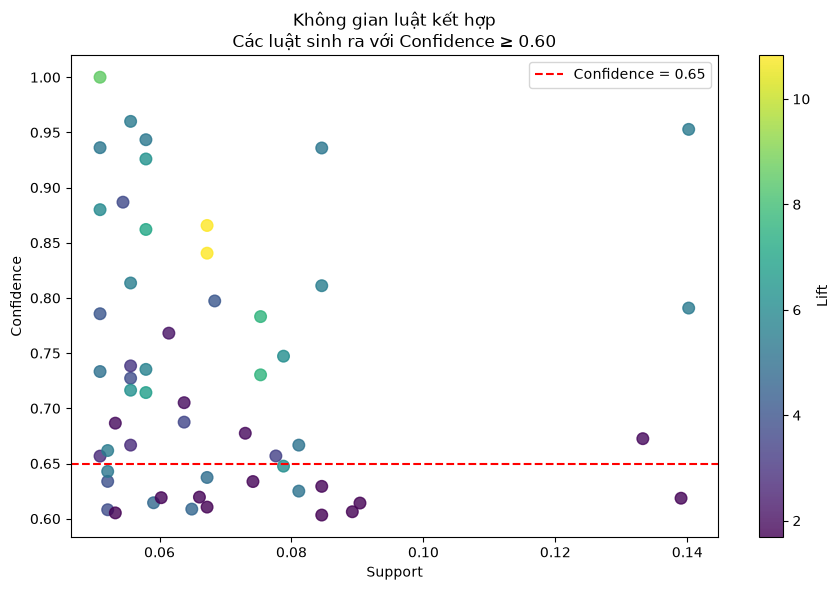

In [68]:
fig, ax = plt.subplots(figsize=(9, 6))

points = ax.scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    cmap="viridis",
    s=70,
    alpha=0.8
)

fig.colorbar(points, ax=ax, label="Lift")

ax.axhline(
    CHOSEN_CONFIDENCE,
    color="red",
    linestyle="--",
    label=f"Confidence = {CHOSEN_CONFIDENCE}"
)

ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title(
    "Không gian luật kết hợp\n"
    "Các luật sinh ra với Confidence ≥ 0.60"
)

ax.legend()
plt.tight_layout()
fig.savefig(
    figures_dir / "association_rules_space.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


### Tổng hợp kết quả khai phá luật

Với 863 giao dịch, nhóm chọn support 0.05,
confidence tối thiểu 0.65 và lift lớn hơn 1.2.

Thuật toán tìm được 227 tập phổ biến và sinh 55 luật
có confidence từ 0.60. Sau khi lọc theo confidence 0.65
và lift lớn hơn 1.2, còn 37 luật. Bước loại dư thừa
loại 3 luật, còn 34 luật.

Các luật còn lại bao gồm quan hệ giữa công nghệ,
phương pháp làm việc, kỹ năng mềm và lĩnh vực nghiệp vụ.
Nhóm lựa chọn các luật phù hợp với câu hỏi nghiên cứu
để phân tích chi tiết.


### Phân tích một số luật tiêu biểu

**Kubernetes ⇒ Docker**

Luật được hỗ trợ bởi 68 tin, tương ứng support 7,88%.
Trong các tin đề cập Kubernetes, 74,73% cũng đề cập Docker.
Lift bằng 6,14 cho thấy tỷ lệ đề cập Docker trong nhóm này
cao gấp khoảng 6,14 lần tỷ lệ Docker trong toàn bộ mẫu.
Conviction của luật là 3,48.

**Docker ⇒ CI/CD**

Luật được hỗ trợ bởi 70 tin, tương ứng support 8,11%.
Trong các tin đề cập Docker, 66,67% cũng đề cập CI/CD.
Lift đạt 5,14 và Conviction đạt 2,61.

**{CI/CD, Kubernetes} ⇒ Docker**

Luật được hỗ trợ bởi 50 tin, tương ứng support 5,79%.
Trong các tin đồng thời đề cập CI/CD và Kubernetes,
86,21% cũng đề cập Docker. Lift đạt 7,09 và
Conviction đạt 6,37.

Các kết quả cho thấy những công nghệ này thường được
đề cập cùng nhau trong mẫu tuyển dụng của nhóm.
Chúng không chứng minh quan hệ nhân quả hoặc yêu cầu
bắt buộc của mọi vị trí.

### Lưu ý khi diễn giải luật

Lift lớn hơn 1,2 thể hiện sự đồng xuất hiện cao hơn mức kỳ vọng theo giả định độc lập trong mẫu. Conviction được xem cùng Support, Confidence và số tin hỗ trợ; không dùng một chỉ số riêng lẻ để kết luận luật hữu ích.

- `Agile` và `Scrum` có thể cùng được tạo ra khi tách nhãn `agile/scrum`. Luật giữa hai nhãn này chịu ảnh hưởng của cách chuẩn hóa, nên không xem là một phát hiện độc lập hoàn toàn.
- `AWS` và `Cloud` có quan hệ giữa công nghệ cụ thể và nhóm công nghệ. Khi diễn giải cần xét quan hệ bao hàm giữa các nhãn.
- `Ngân hàng` và `tài chính` là nhãn lĩnh vực nghiệp vụ. Có thể phân tích chúng để hiểu bối cảnh tuyển dụng, nhưng cần phân biệt với các bộ kỹ năng công nghệ.

Các luật cần được đối chiếu với nội dung tin tuyển dụng. Kết quả phụ thuộc vào chất lượng trích xuất kỹ năng, phạm vi thu thập và ngưỡng đã chọn; cần chạy lại khi nhóm cập nhật dữ liệu.


## Bước 2.5: Phân lớp nhóm lương

Dùng `salary_df` hiện có; nhãn từ trung điểm khoảng lương là <15, 15–30 và >30 triệu VND. Các giá trị USD đã quy đổi theo giả định 26.000 VND/USD; nhãn không phải lương thực nhận và kỳ lương chưa xác minh.

In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_fscore_support

model_df = salary_df.copy()
salary_labels = ["Dưới 15 triệu", "15–30 triệu", "Trên 30 triệu"]
y_salary = pd.Series(np.select(
    [model_df["salary_mid_million"] < 15, model_df["salary_mid_million"] <= 30],
    salary_labels[:2], default=salary_labels[2]), index=model_df.index)
skill_cols = basket.columns.tolist()
X_salary = basket.loc[model_df.index].copy()
X_salary["experience"] = model_df["experience"]
groups_salary = (model_df["company_name"].str.strip().str.casefold() + " | "
                 + model_df["job_title"].str.strip().str.casefold())
display(y_salary.value_counts().reindex(salary_labels))

Dưới 15 triệu     82
15–30 triệu      172
Trên 30 triệu     84
Name: count, dtype: int64

### Nhận xét

Có 338 tin đủ hai cận lương để tạo ba lớp. Nhãn được xác định từ trung điểm khoảng công bố, theo các ngưỡng cố định; các cột lương và chức danh không đưa vào X.

### Chia train/test

Giữ các tin cùng công ty và chức danh trong một nhóm chia. Dành khoảng 20% cho test, chỉ dùng CV ba fold trong train để chọn tham số.

In [70]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_ids, test_ids = next(splitter.split(X_salary, y_salary, groups_salary))
X_train, X_test = X_salary.iloc[train_ids], X_salary.iloc[test_ids]
y_train, y_test = y_salary.iloc[train_ids], y_salary.iloc[test_ids]
groups_train = groups_salary.iloc[train_ids]
assert set(groups_train).isdisjoint(set(groups_salary.iloc[test_ids]))
assert set(y_train) == set(y_test) == set(salary_labels)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})
        .reindex(salary_labels).fillna(0).astype(int))

,train,test
Dưới 15 triệu,65,17
15–30 triệu,138,34
Trên 30 triệu,67,17


### Nhận xét

Train có 270 tin và test có 68 tin. Các tin cùng cặp công ty–chức danh không nằm ở hai phía; cách nhóm này vẫn có thể bỏ sót tin đăng lại khác tên.

### Huấn luyện Decision Tree và Random Forest

Đầu vào gồm kỹ năng và kinh nghiệm. Encoder nằm trong Pipeline; chọn tham số và mô hình bằng Macro F1 trong CV, có khảo sát `ccp_alpha` cho Decision Tree.

In [71]:
preprocess = ColumnTransformer([
    ("skills", "passthrough", skill_cols),
    ("experience", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["experience"])
])
models = {
    "DecisionTree": DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1)
}
grids = {
    "DecisionTree": {"model__max_depth": [4, 8, None], "model__ccp_alpha": [0.0, 0.005, 0.02]},
    "RandomForest": {"model__max_depth": [10, None], "model__min_samples_leaf": [2, 5]}
}
searches, cv_rows = {}, []
for name, model in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("model", model)])
    search = GridSearchCV(pipeline, grids[name], scoring="f1_macro",
                          cv=cv, return_train_score=True, n_jobs=1, error_score="raise")
    search.fit(X_train, y_train, groups=groups_train)
    searches[name] = search
    cv_rows.append({"model": name, "cv_macro_f1": search.best_score_,
                    "best_params": search.best_params_})
cv_scores = pd.DataFrame(cv_rows)
display(cv_scores)
selected_name = cv_scores.sort_values("cv_macro_f1", ascending=False).iloc[0]["model"]
print("Mô hình chọn trước khi mở test:", selected_name)

,model,cv_macro_f1,best_params
0,DecisionTree,0.612937,"{'model__ccp_alpha': 0.02, 'model__max_depth': 4}"
1,RandomForest,0.477692,"{'model__max_depth': None, 'model__min_samples..."


Mô hình chọn trước khi mở test: DecisionTree


### Nhận xét

Chọn DecisionTree bằng CV Macro F1 = 0,6129, trước khi đánh giá test. Tham số được chọn: ccp_alpha=0.02, max_depth=4.

### Đánh giá mô hình

Báo precision, recall, Macro F1 và confusion matrix trên cùng tập test sau khi đã chọn mô hình bằng CV.

DecisionTree
               precision    recall  f1-score   support

Dưới 15 triệu       0.67      0.35      0.46        17
  15–30 triệu       0.55      0.50      0.52        34
Trên 30 triệu       0.50      0.82      0.62        17

     accuracy                           0.54        68
    macro avg       0.57      0.56      0.54        68
 weighted avg       0.57      0.54      0.53        68



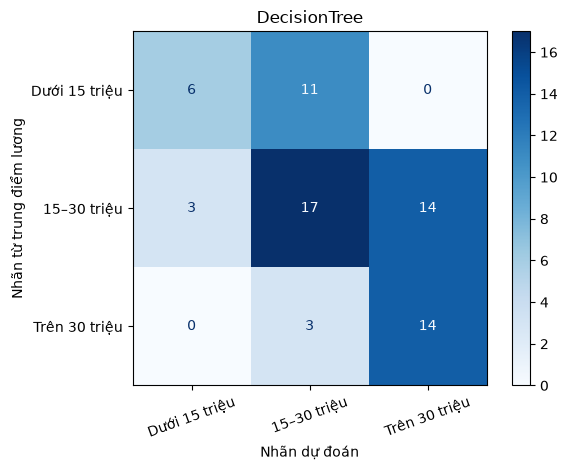

RandomForest
               precision    recall  f1-score   support

Dưới 15 triệu       0.62      0.29      0.40        17
  15–30 triệu       0.53      0.91      0.67        34
Trên 30 triệu       0.50      0.06      0.11        17

     accuracy                           0.54        68
    macro avg       0.55      0.42      0.39        68
 weighted avg       0.55      0.54      0.46        68



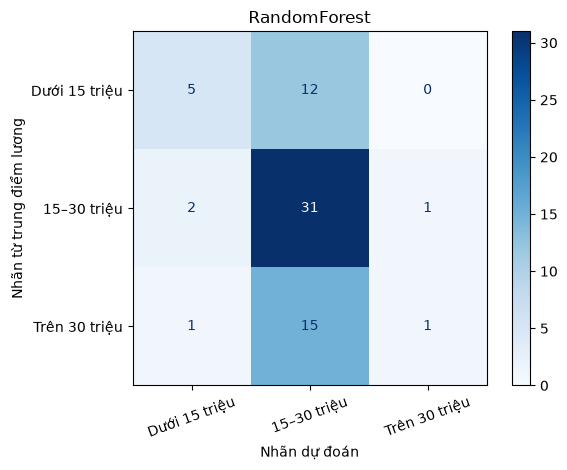

,model,accuracy,precision_macro,recall_macro,macro_f1
0,DecisionTree,0.544118,0.571685,0.558824,0.535613
1,RandomForest,0.544118,0.553161,0.421569,0.393059


In [72]:
test_predictions = pd.DataFrame({"source_url": model_df.loc[X_test.index, "source_url"], "actual": y_test})
metric_rows = []
for name, search in searches.items():
    predicted = search.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predicted, labels=salary_labels, average="macro", zero_division=0)
    metric_rows.append({"model": name, "accuracy": float((y_test == predicted).mean()), "precision_macro": precision,
                        "recall_macro": recall, "macro_f1": f1})
    test_predictions[name] = predicted
    print(name)
    print(classification_report(y_test, predicted, labels=salary_labels, zero_division=0))
    cm = ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=salary_labels, cmap="Blues", xticks_rotation=20)
    cm.ax_.set(title=name, xlabel="Nhãn dự đoán", ylabel="Nhãn từ trung điểm lương")
    plt.tight_layout()
    plt.savefig(figures_dir / f"confusion_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
classification_metrics = pd.DataFrame(metric_rows)
display(classification_metrics)

### Nhận xét

DecisionTree: Macro F1 0,5356, accuracy 54,41%; RandomForest: Macro F1 0,3931, accuracy 54,41%. Kết quả chỉ áp dụng nhóm trung điểm lương trong tập dữ liệu hiện tại; không đọc thành độ chính xác dự báo lương thực nhận.

### Khảo sát cắt tỉa cây

Giữ độ sâu tốt nhất theo CV và so sánh điểm train/validation ở các giá trị alpha. `mean_test_score` của GridSearchCV là validation CV, không phải holdout test.

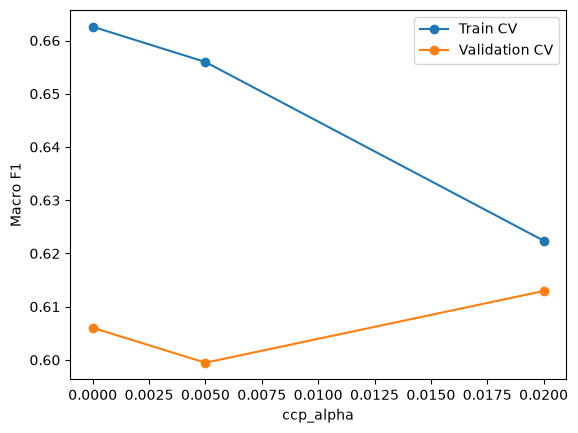

In [73]:
tree_cv = pd.DataFrame(searches["DecisionTree"].cv_results_)
best_depth = searches["DecisionTree"].best_params_["model__max_depth"]
same_depth = tree_cv["params"].map(lambda p: p["model__max_depth"] == best_depth)
pruning = tree_cv.loc[same_depth].sort_values("param_model__ccp_alpha")
alpha = pruning["param_model__ccp_alpha"].astype(float)
plt.plot(alpha, pruning["mean_train_score"], "o-", label="Train CV")
plt.plot(alpha, pruning["mean_test_score"], "o-", label="Validation CV")
plt.xlabel("ccp_alpha")
plt.ylabel("Macro F1")
plt.legend()
plt.savefig(figures_dir / "tree_pruning.png", dpi=150, bbox_inches="tight")
plt.show()

### Nhận xét

Decision Tree chọn ccp_alpha = 0.02 và max_depth = 4 trong lưới CV. Việc khảo sát alpha không có nghĩa alpha dương luôn tốt hơn; giới hạn độ sâu và min_samples_leaf vẫn hạn chế độ phức tạp cây.

### Phân tích dự đoán sai

Đọc URL, kinh nghiệm và khoảng lương gốc của các tin sai. Quy tắc chia nhóm chỉ nhận diện cùng công ty/chức danh, chưa phát hiện mọi tin đăng lại với tên khác.

In [74]:
predicted = searches[selected_name].predict(X_test)
errors = model_df.loc[X_test.index,
    ["source_url", "job_title", "experience", "salary_raw", "salary_mid_million"]].copy()
errors["actual"] = y_test
errors["predicted"] = predicted
errors = errors.loc[errors["actual"] != errors["predicted"]]
print("Số tin dự đoán sai:", len(errors), "/", len(y_test))
display(errors.head(10))
classification_metrics.to_csv(tables_dir / "salary_classification_metrics.csv", index=False)
errors.to_csv(tables_dir / "salary_misclassified_samples.csv", index=False)
cv_scores.to_csv(tables_dir / "salary_cv_scores.csv", index=False)
test_predictions.to_csv(tables_dir / "salary_predictions.csv", index=False)

Số tin dự đoán sai: 31 / 68


,source_url,job_title,experience,salary_raw,salary_mid_million,actual,predicted
2,https://www.topcv.vn/viec-lam/chuyen-vien-kiem...,Chuyên Viên Kiểm Thử Phần Mềm,2 năm,10 - 15 triệu,12.5,Dưới 15 triệu,15–30 triệu
14,https://www.topcv.vn/viec-lam/software-develop...,Software Developer (C++/ Golang ),Không yêu cầu,10 - 28 triệu,19.0,15–30 triệu,Dưới 15 triệu
51,https://www.topcv.vn/viec-lam/business-analyst...,Business Analyst / Project Manager ( BA /PM) -...,1 năm,25 - 40 triệu,32.5,Trên 30 triệu,15–30 triệu
67,https://www.topcv.vn/viec-lam/nhan-vien-phan-t...,Nhân Viên Phân Tích Nghiệp Vụ,1 năm,8 - 15 triệu,11.5,Dưới 15 triệu,15–30 triệu
76,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Chuyên Viên Phân Tích Nghiệp Vụ Banking,5 năm,20 - 30 triệu,25.0,15–30 triệu,Trên 30 triệu
103,https://www.topcv.vn/viec-lam/android-develope...,Android Developer (Lương Upto 20 Triệu) Đi Làm...,Dưới 1 năm,10 - 20 triệu,15.0,15–30 triệu,Dưới 15 triệu
184,https://www.topcv.vn/viec-lam/senior-qa-engine...,Senior QA Engineer,3 năm,15 - 20 triệu,17.5,15–30 triệu,Trên 30 triệu
197,https://www.topcv.vn/viec-lam/devops-engineer-...,DevOps Engineer (Intermediate / Middle Level),3 năm,15 - 30 triệu,22.5,15–30 triệu,Trên 30 triệu
248,https://www.topcv.vn/viec-lam/truong-nhom-andr...,Trưởng Nhóm Android Developer,4 năm,20 - 26 triệu,23.0,15–30 triệu,Trên 30 triệu
254,https://www.topcv.vn/viec-lam/truong-nhom-phan...,Trưởng Nhóm Phân Tích Nghiệp Vụ,4 năm,13 - 18 triệu,15.5,15–30 triệu,Trên 30 triệu


### Nhận xét

DecisionTree dự đoán sai 31/68 tin test. Bảng lỗi giúp đối chiếu kỹ năng, kinh nghiệm và khoảng lương gốc; khoảng lương rộng, nhãn gần biên và đặc trưng chưa đầy đủ là các khả năng cần kiểm tra, chưa phải nguyên nhân đã được chứng minh.
